# COMP 1030 Project 2.2: Cross-modal retrieval of mobile app screens and text summaries

**Task.** Given a screenshot of an Android app screen, retrieve its human-written summary (screen to text, *i2t*),
and given a summary, retrieve the matching screen (text to screen, *t2i*). Data: RICO-Screen2Words
(22,417 screens, 5 captions each).

**Approach (from the Group 21 proposal).** Frozen pretrained encoders produce features once; small heads are trained on top.

| Method | Type | Role |
|---|---|---|
| Random scorer | baseline | sanity floor |
| Ridge regression (text features mapped into image space) | linear baseline | success target reference |
| Early fusion (concatenate + project, MLP match score) | fusion technique 1 | models feature interactions, pairwise cost |
| Contrastive dual encoder (CLIP-style projections, symmetric multi-positive InfoNCE) | fusion technique 2 | shared embedding space, cheap retrieval |
| Hybrid: contrastive retrieves top-K, early fusion re-ranks | deployment design | combines both |
| Cross-attention fusion (caption tokens attend to screen regions), re-ranks contrastive top-20 | fusion technique 3 (intermediate) | token-level interactions |
| CLIP ViT-B/32 zero-shot and CLIP features + our head | **reference only** | comparison with a large pretrained model |

**Success criterion (proposal).** The best learned multimodal model improves Recall@10 by at least 5 absolute
percentage points over ridge regression in **both** directions. Recall@1/5, MRR and median rank are also reported.

**How to run.** Runtime > Change runtime type > **T4 GPU**, then Runtime > Run all. Total time roughly 1.5 hours on a
free T4 (features are cached to Google Drive, so a re-run after a disconnect skips extraction). Every number used in the
report is printed in the **Report Fact Sheet** at the end (Section 17) and saved under `outputs/`.

| Section | Content | Rubric |
|---|---|---|
| 0-2 | Setup, data loading, data quality assessment, cleaning, privacy review | C1, C5 |
| 4 | Image and text preprocessing, feature extraction (3 image encoders, 2 BERT poolings, CLIP ref) | C1, C2 |
| 5 | Leakage-aware split (apps linked by near-duplicate screens) | C1, C2 |
| 6-8 | Metrics, models, training | C2 |
| 9 | Feature extractor selection on validation data | C2 |
| 10-11 | Main experiments (3 seeds) and ablations | C2, C3 |
| 10.2 | Cross-attention (intermediate) fusion re-ranker | C2 |
| 12-15 | Results, overfitting, efficiency, bias, bias-mitigation experiment, failure cases | C3, C5 |
| 16-17 | Changes from proposal, fact sheet | C1, C4 |

## 0. Setup

In [1]:
import os, sys
SMOKE = os.environ.get("SMOKE") == "1"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    os.system("pip install -q 'datasets>=3' 'transformers>=4.44' scikit-learn scipy")
    from google.colab import drive
    drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
# All the output folders, device settings, visualisation style, timing utilities, and evidence collection used throughout the experiment is prepared.

import io, re, gc, json, math, time, copy, random, warnings, platform, textwrap, shutil
from pathlib import Path
from contextlib import contextmanager
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib
if not IN_COLAB and SMOKE:
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from PIL import Image
from tqdm.auto import tqdm
try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")

CFG = dict(
    DATASET_ID="rootsautomation/RICO-Screen2Words",
    DATASET_FALLBACK="bevaya/RICO-Screen2Words",
    SEED=42,
    SUBSAMPLE=None,
    EDA_IMAGE_SAMPLE=1000,
    SPLIT_FRACS=(0.80, 0.10, 0.10),
    NEAR_DUP_T=0.95,
    MAX_COMPONENT_SHARE=0.20,
    PII_EXCLUDE_ROWS=[],
    IMG_SIZE=224,
    JPEG_DRAFT=True,
    IMAGE_ENCODERS=["resnet50", "efficientnet_b0", "vit_b_16"],
    BERT="bert-base-uncased",
    TEXT_MAX_LEN=16,
    CLIP="openai/clip-vit-base-patch32",
    RUN_CLIP_REFERENCE=True,
    BATCH_IMG=64, BATCH_TXT=512, NUM_WORKERS=0,
    PROJ_HIDDEN=512, PROJ_OUT=256, DROPOUT=0.3, INPUT_DROPOUT=0.1,
    EPOCHS=60, PATIENCE=8, LR=1e-3, WD=1e-2,
    BATCH_SCREENS=256,
    BATCH_SCREENS_EF=128,
    SEEDS=[0, 1, 2],
    RIDGE_ALPHAS=[1e2, 1e3, 3e3, 1e4, 3e4, 1e5, 3e5],
    HYBRID_K=50, HYBRID_LAMBDAS=[0.0, 0.25, 0.5, 1.0, 2.0, 4.0],
    RUN_ABLATIONS=True,
    RUN_CROSS_ATTN=True,
    XA_GRID=(7, 3),
    XA_DIM=256, XA_HEADS=4, XA_LAYERS=2, XA_DROPOUT=0.1, XA_LR=3e-4,
    XA_ANCHORS=16, XA_NEIGHBOURS=3,
    XA_EPOCHS=8, XA_PATIENCE=2, XA_K=20, XA_LAMBDAS=[0.5, 1.0, 2.0, 4.0, None],
    MITIGATION_BETAS=[0.5, 1.0],
    BOOT_REPS=1000,
    SUCCESS_MARGIN=5.0,
    MIN_CAT_SCREENS=20,
    LATENCY_GALLERIES=[1_000, 10_000, 100_000, 1_000_000],
    PRETRAINED=True,
)
OUT = Path("outputs")
CACHE = Path("/content/drive/MyDrive/comp1030_p22_cache") if IN_COLAB else Path("cache")
if SMOKE:
    CFG.update(SUBSAMPLE=None, EDA_IMAGE_SAMPLE=60, IMAGE_ENCODERS=["resnet50", "efficientnet_b0"], EPOCHS=15, PATIENCE=4,
               SEEDS=[0, 1], BOOT_REPS=50, BATCH_SCREENS=32, BATCH_SCREENS_EF=16, BATCH_IMG=16, NUM_WORKERS=0,
               LATENCY_GALLERIES=[1_000, 10_000], MIN_CAT_SCREENS=5, XA_EPOCHS=2, XA_PATIENCE=1, XA_K=10, XA_DIM=64, XA_LAYERS=1, PRETRAINED=False, HYBRID_K=10,
               PII_EXCLUDE_ROWS=[3], NEAR_DUP_T=0.9999)
    CACHE = Path("cache_smoke")
for p in [OUT / "figures", OUT / "tables", CACHE]:
    p.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# Colour palette: fixed hue per method so a method keeps its colour in every figure.
INK, MUTED, GRID = "#0b0b0b", "#898781", "#e1e0d9"
C = dict(blue="#2a78d6", orange="#eb6834", aqua="#1baf7a", yellow="#eda100", magenta="#e87ba4",
         green="#008300", violet="#6250d6", red="#e34948")
METHOD_COLOR = {"Random": MUTED, "Ridge": C["blue"], "Early fusion": C["orange"], "Contrastive": C["aqua"],
                "Hybrid (contrastive + EF re-rank)": C["magenta"], "CLIP zero-shot (ref)": C["violet"],
                "CLIP feats + contrastive head (ref)": C["yellow"], "Cross-attention re-rank": C["green"]}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c3c2b7",
                     "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
                     "axes.titlesize": 11, "axes.labelsize": 10, "legend.frameon": False, "font.size": 9.5,
                     "axes.prop_cycle": matplotlib.cycler(color=list(C.values()))})


def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)


seed_everything(CFG["SEED"])


@contextmanager
def timer():
    if DEVICE == "cuda": torch.cuda.synchronize()
    box = {}; t0 = time.perf_counter()
    try:
        yield box
    finally:
        if DEVICE == "cuda": torch.cuda.synchronize()
        box["s"] = time.perf_counter() - t0


def gpu_reset():
    if DEVICE == "cuda": torch.cuda.reset_peak_memory_stats()


def gpu_peak_gb():
    return torch.cuda.max_memory_allocated() / 1e9 if DEVICE == "cuda" else float("nan")


def amp():
    return torch.autocast(device_type="cuda", dtype=torch.float16, enabled=(DEVICE == "cuda"))


# Every number the report needs
EVIDENCE = {}
def _native(x):
    if isinstance(x, torch.Tensor): x = x.detach().cpu().numpy()
    if isinstance(x, np.integer): return int(x)
    if isinstance(x, (np.floating, float)): return round(float(x), 4)
    if isinstance(x, np.ndarray): return _native(x.tolist())
    if isinstance(x, (list, tuple)): return [_native(v) for v in x]
    if isinstance(x, dict): return {str(k): _native(v) for k, v in x.items()}
    return x
def ev(key, value, show=True):
    EVIDENCE[key] = _native(value)
    if show: print(f"[evidence] {key} = {EVIDENCE[key]}")
def save_fig(fig, name):
    fig.savefig(OUT / "figures" / f"{name}.png", dpi=200, bbox_inches="tight")
    plt.show() if not SMOKE else None
    plt.close(fig)
def save_tbl(df, name, index=True):
    df.to_csv(OUT / "tables" / f"{name}.csv", index=index)

import transformers, datasets, torchvision
ev("python", platform.python_version()); ev("torch", torch.__version__); ev("torchvision", torchvision.__version__)
ev("transformers", transformers.__version__); ev("datasets", datasets.__version__); ev("device", DEVICE)
if DEVICE == "cuda":
    ev("gpu_name", torch.cuda.get_device_name(0))
else:
    print("WARNING: no GPU. Use Runtime > Change runtime type > T4 GPU.")

[evidence] python = 3.13.16
[evidence] torch = 2.14.1+cu130
[evidence] torchvision = 0.29.1+cu130
[evidence] transformers = 5.22.1
[evidence] datasets = 4.8.5
[evidence] device = cuda
[evidence] gpu_name = Tesla T4


## 1. Load the dataset
Only the metadata columns are converted to pandas. The screenshot column is kept as raw JPEG bytes (`decode=False`)
so images are decoded once, inside the feature-extraction workers, at reduced JPEG scale.

In [3]:
from datasets import load_dataset, concatenate_datasets, Image as HFImage

META_COLS = ["screenId", "captions", "app_package_name", "play_store_name", "category"]


def load_rico():
    if SMOKE:
        from smoke_data import make_fake_dataset
        return make_fake_dataset()
    last = None
    for did in [CFG["DATASET_ID"], CFG["DATASET_FALLBACK"]]:
        try:
            return load_dataset(did), did
        except Exception as e:
            print(f"Could not load {did}: {e!r}"); last = e
    raise last


dsd, USED_ID = load_rico()
SPLIT_ORDER = [s for s in ["train", "val", "validation", "test"] if s in dsd]
ds = concatenate_datasets([dsd[s] for s in SPLIT_ORDER])
orig_split = np.concatenate([[s] * len(dsd[s]) for s in SPLIT_ORDER])
ev("dataset_id_used", USED_ID); ev("original_split_sizes", {s: len(dsd[s]) for s in SPLIT_ORDER})

meta = ds.select_columns(META_COLS).to_pandas()
meta["_row"] = np.arange(len(meta)); meta["orig_split"] = orig_split
ds_img = ds.select_columns(["image"]).cast_column("image", HFImage(decode=False))
if CFG["SUBSAMPLE"]:
    meta = meta.sample(CFG["SUBSAMPLE"], random_state=CFG["SEED"]).sort_values("_row").reset_index(drop=True)
print(meta.shape); display(meta.head(3))

README.md:   0%|          | 0.00/6.13k [00:00<?, ?B/s]

data/train-00000-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  216MB            

data/train-00000-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  219MB            

data/train-00001-of-00008.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00008.parquet: reconstructing file:   0%|          |  0.00B /  225MB            

... (20 outputs left out)

Generating val split:   0%|          | 0/2364 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/4310 [00:00<?, ? examples/s]

[evidence] dataset_id_used = rootsautomation/RICO-Screen2Words
[evidence] original_split_sizes = {'train': 15743, 'val': 2364, 'test': 4310}
(22417, 7)


,screenId,captions,app_package_name,play_store_name,category,_row,orig_split
0,2,[notification displaying a calendar with done ...,yong.app.videoeditor,Video Maker Pro Free,Video Players & Editors,0,train
1,3,[display shows course of action in the fitness...,yong.app.videoeditor,Video Maker Pro Free,Video Players & Editors,1,train
2,4,"[display of screen shows workout summary, page...",yong.app.videoeditor,Video Maker Pro Free,Video Players & Editors,2,train


## 2. Data quality assessment (text and metadata)
Checks: missing values, captions per screen, empty and duplicate captions, caption length, vocabulary, non-English text,
caption reuse across screens (text-only ambiguity), malformed categories, category and app imbalance.

In [4]:
def norm_text(s):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]+", " ", str(s).lower())).strip()


meta["caps"] = meta["captions"].map(lambda x: [str(t) for t in (x if x is not None else [])])
cap_df = pd.DataFrame([(i, c) for i, cl in zip(meta.index, meta["caps"]) for c in cl], columns=["m", "caption"])
cap_df["norm"] = cap_df["caption"].map(norm_text)
cap_df["n_words"] = cap_df["caption"].str.split().str.len()

ev("n_screens_raw", len(meta)); ev("n_captions_raw", len(cap_df))
ev("missing_values_per_column", meta[META_COLS].isna().sum().to_dict())
ev("captions_per_screen", meta["caps"].str.len().value_counts().sort_index().to_dict())
ev("empty_captions", int((cap_df["norm"] == "").sum()))
ev("caption_words_median_p95_max", [cap_df["n_words"].median(), cap_df["n_words"].quantile(.95), cap_df["n_words"].max()])
vocab = Counter(w for n in cap_df["norm"] for w in n.split())
ev("vocab_size", len(vocab)); ev("nonascii_caption_share", cap_df["caption"].map(lambda s: any(ord(ch) > 127 for ch in s)).mean())
screens_per_text = cap_df.groupby("norm")["m"].nunique()
cap_df["text_screens"] = cap_df["norm"].map(screens_per_text)
ev("share_captions_reused_across_screens", (cap_df["text_screens"] > 1).mean())
ev("top_generic_captions", screens_per_text.sort_values(ascending=False).head(8).to_dict())
dup_within = sum(len(cl) - len({norm_text(c) for c in cl}) for cl in meta["caps"])
ev("duplicate_captions_within_screen", dup_within)

valid_cat = meta["category"].fillna("").str.match(r"^[A-Za-z][A-Za-z &]+$")
ev("malformed_category_rows", int((~valid_cat).sum()))
ev("malformed_category_values", meta.loc[~valid_cat, "category"].value_counts().head(5).to_dict())
meta["category_clean"] = np.where(valid_cat, meta["category"], "Unknown")
vc = meta["category_clean"].value_counts()
ev("n_categories", len(vc)); ev("category_largest_smallest", {**vc.head(2).to_dict(), **vc.tail(2).to_dict()})
ev("category_imbalance_ratio_max_over_min", vc.max() / max(1, vc[vc.index != "Unknown"].min()))
spa = meta.groupby("app_package_name").size()
ev("n_apps", len(spa)); ev("screens_per_app_median_max", [spa.median(), spa.max()])

# sensitive screen types (privacy and fairness subgroup)
SENSITIVE = ["login", "log in", "sign in", "sign up", "password", "payment", "credit card", "bank", "wallet",
             "account", "profile", "chat", "message", "address", "phone number", "email"]
sens_pat = re.compile("|".join(re.escape(w) for w in SENSITIVE))
meta["sensitive"] = meta["caps"].map(lambda cl: any(sens_pat.search(c.lower()) for c in cl))
ev("share_screens_sensitive_function", meta["sensitive"].mean())
PII = {"email": r"[\w\.-]+@[\w\.-]+\.\w+", "phone": r"(?<!\d)\+?\d[\d\-\s().]{8,}\d(?!\d)", "url": r"(?:https?://|www\.)\S+",
       "handle": r"(?<!\w)@\w{3,}"}
ev("pii_regex_hits_in_captions", {k: int(cap_df["caption"].str.contains(p, regex=True).sum()) for k, p in PII.items()})

[evidence] n_screens_raw = 22417
[evidence] n_captions_raw = 112085
[evidence] missing_values_per_column = {'screenId': 0, 'captions': 0, 'app_package_name': 0, 'play_store_name': 0, 'category': 0}
[evidence] captions_per_screen = {'5': 22417}
[evidence] empty_captions = 0
[evidence] caption_words_median_p95_max = [7.0, 10.0, 12]
[evidence] vocab_size = 6787
[evidence] nonascii_caption_share = 0.0
[evidence] share_captions_reused_across_screens = 0.3179
[evidence] top_generic_captions = {'welcome page': 635, 'login page': 389, 'sign in page': 346, 'settings page': 296, 'sign up page': 250, 'display of a pop up': 208, 'home page': 202, 'page displaying different options': 192}
[evidence] duplicate_captions_within_screen = 979
[evidence] malformed_category_rows = 1
[evidence] malformed_category_values = {'000 - 1': 1}
[evidence] n_categories = 28
[evidence] category_largest_smallest = {'Shopping': 1648, 'Social': 1641, 'Events': 55, 'Unknown': 1}
[evidence] category_imbalance_ratio_max_o

### 2.1 Cleaning rules and their impact
Normalise whitespace, drop empty captions, drop duplicate captions inside one screen (they would act as two identical
positives), map malformed categories to `Unknown`, drop screens flagged in the manual privacy review, drop screens left
with no caption. Corrupt images are detected and dropped during feature extraction (Section 4).

In [5]:
def clean_caps(cl):
    seen, out = set(), []
    for c in cl:
        c2 = re.sub(r"\s+", " ", c).strip(); k = norm_text(c2)
        if k and k not in seen:
            seen.add(k); out.append(c2)
    return out


meta["caps_clean"] = meta["caps"].map(clean_caps)
pii_mask = meta["_row"].isin(CFG["PII_EXCLUDE_ROWS"])
stages = [("raw", len(meta), int(meta["caps"].str.len().sum()))]
meta_c = meta[~pii_mask]
stages.append(("minus manual-review PII screens", len(meta_c), int(meta_c["caps"].str.len().sum())))
meta_c = meta_c[meta_c["caps_clean"].str.len() > 0]
stages.append(("after caption cleaning", len(meta_c), int(meta_c["caps_clean"].str.len().sum())))
meta_c = meta_c.reset_index(drop=True)
impact = pd.DataFrame(stages, columns=["stage", "screens", "captions"])
impact["captions_kept_%"] = (impact["captions"] / impact["captions"].iloc[0] * 100).round(2)
print("Table 1: cleaning impact"); display(impact); save_tbl(impact, "t01_cleaning_impact", index=False)
ev("cleaning_impact", impact.to_dict("records"))

# flattened caption table: every caption has an id, an owner screen and a text id
cap_text, cap_owner = [], []
for m, cl in enumerate(meta_c["caps_clean"]):
    cap_text += cl; cap_owner += [m] * len(cl)
cap_owner = np.array(cap_owner)
cap_cnt = meta_c["caps_clean"].str.len().values
cap_start = np.concatenate([[0], np.cumsum(cap_cnt)[:-1]])
cap_norm = [norm_text(c) for c in cap_text]
cap_tid = pd.factorize(pd.Series(cap_norm))[0]
cap_generic = pd.Series(cap_norm).map(screens_per_text).fillna(1).values
N_SCREENS, N_CAPS = len(meta_c), len(cap_text)
print(f"{N_SCREENS} screens, {N_CAPS} captions after cleaning")

Table 1: cleaning impact


,stage,screens,captions,captions_kept_%
0,raw,22417,112085,100.00
1,minus manual-review PII screens,22417,112085,100.00
2,after caption cleaning,22417,111106,99.13


[evidence] cleaning_impact = [{'stage': 'raw', 'screens': 22417, 'captions': 112085, 'captions_kept_%': 100.0}, {'stage': 'minus manual-review PII screens', 'screens': 22417, 'captions': 112085, 'captions_kept_%': 100.0}, {'stage': 'after caption cleaning', 'screens': 22417, 'captions': 111106, 'captions_kept_%': 99.13}]
22417 screens, 111106 captions after cleaning


### 2.2 Token-length check for BERT, and figure of text/metadata quality

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[evidence] bert_tokens_median_p99_max = [9.0, 13.0, 18]
[evidence] share_truncated_at_max_len = 0.0001


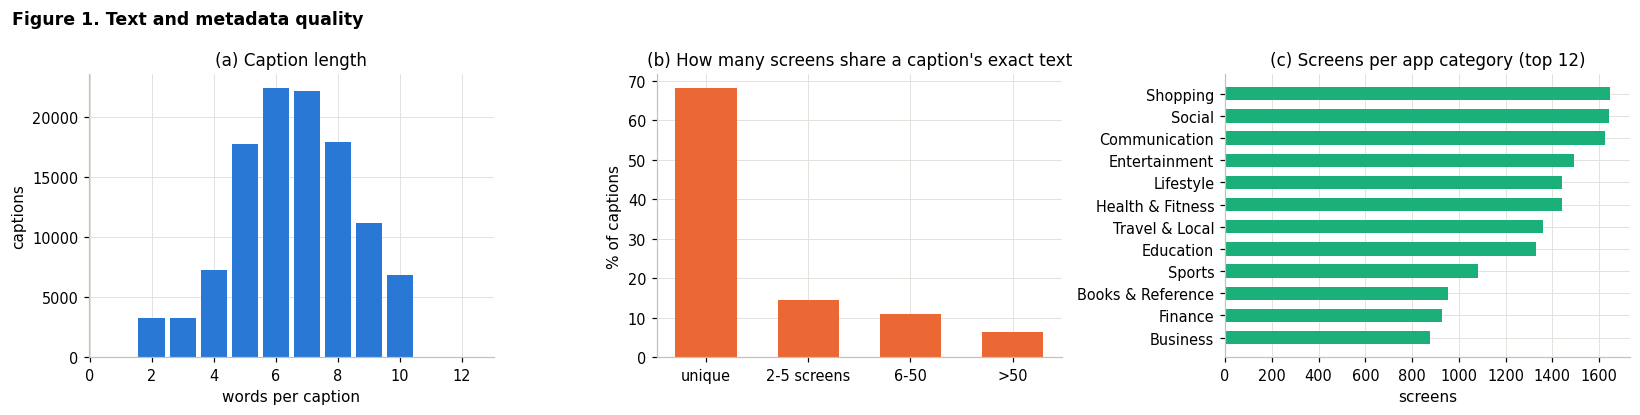

In [6]:
from transformers import AutoTokenizer, AutoModel

def get_bert_tokenizer():
    if SMOKE:
        from smoke_data import fake_tokenizer
        return fake_tokenizer()
    return AutoTokenizer.from_pretrained(CFG["BERT"])


tok = get_bert_tokenizer()
tok_lens = np.array([len(x) for x in tok(cap_text, add_special_tokens=True, truncation=False)["input_ids"]])
ev("bert_tokens_median_p99_max", [np.median(tok_lens), np.percentile(tok_lens, 99), tok_lens.max()])
ev("share_truncated_at_max_len", (tok_lens > CFG["TEXT_MAX_LEN"]).mean())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
ax[0].hist(cap_df["n_words"], bins=np.arange(0.5, cap_df["n_words"].max() + 1.5), color=C["blue"], rwidth=0.85)
ax[0].set(title="(a) Caption length", xlabel="words per caption", ylabel="captions")
bins = [0, 1, 5, 50, 1e9]; lab = ["unique", "2-5 screens", "6-50", ">50"]
share = pd.cut(cap_df["text_screens"], bins, labels=lab).value_counts(normalize=True).reindex(lab) * 100
ax[1].bar(lab, share.values, color=C["orange"], width=0.6)
ax[1].set(title="(b) How many screens share a caption's exact text", ylabel="% of captions")
top = vc.head(12).iloc[::-1]
ax[2].barh(top.index, top.values, color=C["aqua"], height=0.6); ax[2].set(title="(c) Screens per app category (top 12)", xlabel="screens")
fig.suptitle("Figure 1. Text and metadata quality", fontweight="bold", x=0.01, ha="left"); fig.tight_layout()
save_fig(fig, "fig01_text_quality")

### 2.3 Image quality on a random sample
Resolution, aspect ratio, colour mode, corrupt files and near-blank screens.

In [7]:
def open_screen(row):
    rec = ds_img[int(row)]["image"]
    return Image.open(io.BytesIO(rec["bytes"])) if rec.get("bytes") else Image.open(rec["path"])


rng = np.random.default_rng(CFG["SEED"])
recs = []
for r in tqdm(rng.choice(meta_c["_row"].values, min(CFG["EDA_IMAGE_SAMPLE"], N_SCREENS), replace=False), desc="image QA"):
    try:
        im = open_screen(r); fmt = im.format; im.load(); w, h = im.size
        g = np.asarray(im.convert("L").resize((64, 64)), dtype=np.float32)
        recs.append(dict(ok=True, w=w, h=h, mode=im.mode, fmt=fmt, std=g.std()))
    except Exception as e:
        recs.append(dict(ok=False, err=repr(e)[:60]))
iq = pd.DataFrame(recs); okq = iq[iq.ok]
ev("img_sample_n", len(iq)); ev("img_sample_corrupt", int((~iq.ok).sum()))
ev("img_resolutions_top", okq.groupby(["w", "h"]).size().sort_values(ascending=False).head(3).to_dict())
ev("img_aspect_median", (okq.w / okq.h).median()); ev("img_modes", okq["mode"].value_counts().to_dict())
ev("img_formats", okq["fmt"].value_counts().to_dict()); ev("img_near_blank", int((okq["std"] < 3).sum()))

image QA:   0%|          | 0/1000 [00:00<?, ?it/s]

[evidence] img_sample_n = 1000
[evidence] img_sample_corrupt = 0
[evidence] img_resolutions_top = {'(1080, 1920)': 748, '(540, 960)': 252}
[evidence] img_aspect_median = 0.5625
[evidence] img_modes = {'RGB': 1000}
[evidence] img_formats = {'JPEG': 1000}
[evidence] img_near_blank = 0


### 2.4 Manual privacy review

In [8]:
SHOW_REVIEW = False
if SHOW_REVIEW:
    g = np.random.default_rng(0); rows = g.choice(meta["_row"].values, 80, replace=False)
    fig, axes = plt.subplots(5, 16, figsize=(24, 10))
    for a, r in zip(axes.flatten(), rows):
        a.imshow(open_screen(r).convert("RGB").resize((108, 192))); a.set_title(f"row {r}", fontsize=7); a.axis("off")
    plt.show()
ev("pii_screens_excluded", len(CFG["PII_EXCLUDE_ROWS"]))

[evidence] pii_screens_excluded = 0


## 4. Preprocessing and feature extraction

The image pipeline scales down JPEG images if necessary (where there are no special demands), converts them to RGB, and then rescales them to 224 × 224 pixels without cropping, while keeping important parts of the interface like the status bars, toolbars and bottom navigation. Images are normalised and using ImageNet statistics for the 3 main encoders and CLIP statistics for the CLIP reference model. Corrupted images are replaced with zero arrays, flagged and excluded from the analysis. Three frozen, ImageNet-pretrained image encoders are compared: ResNet-50 (2048-dimensional global average pooling), EfficientNet-B0 (1280-dimensional features) and ViT-B/16 (768-dimensional [CLS] representation). A single image decode is being shared among the encoders in each batch. Text is whitespace-normalised and passed through a frozen BERT-base model without casement after tokenisation with uncased BERT WordPiece (max wordpiece length 16). The features are extracted from both the [CLS] and the final hidden layer (mean pooling with attention masks). All image and text features are extracted and stored in the fp16 format on Google Drive for subsequent training/evaluation without re-processing of the original images.

In [9]:
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import torchvision.transforms.functional as TF

IMNET_MEAN, IMNET_STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]
CLIP_MEAN, CLIP_STD = [0.48145466, 0.4578275, 0.40821073], [0.26862954, 0.26130258, 0.27577711]
S = CFG["IMG_SIZE"]


class ScreenImages(Dataset):
    def __init__(self, rows): self.rows = [int(r) for r in rows]
    def __len__(self): return len(self.rows)
    def __getitem__(self, i):
        try:
            im = open_screen(self.rows[i])
            if CFG["JPEG_DRAFT"] and im.format == "JPEG":
                im.draft("RGB", (2 * S, 2 * S))
            x = TF.to_tensor(im.convert("RGB").resize((S, S), Image.BICUBIC))
            return TF.normalize(x, IMNET_MEAN, IMNET_STD), TF.normalize(x, CLIP_MEAN, CLIP_STD), True
        except Exception:
            z = torch.zeros(3, S, S); return z, z, False


def build_image_encoders():
    w = CFG["PRETRAINED"]; enc = {}
    if "resnet50" in CFG["IMAGE_ENCODERS"]:
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2 if w else None); m.fc = nn.Identity(); enc["resnet50"] = m
    if "efficientnet_b0" in CFG["IMAGE_ENCODERS"]:
        m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1 if w else None); m.classifier = nn.Identity(); enc["efficientnet_b0"] = m
    if "vit_b_16" in CFG["IMAGE_ENCODERS"]:
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1 if w else None); m.heads = nn.Identity(); enc["vit_b_16"] = m
    return {k: v.to(DEVICE).eval() for k, v in enc.items()}


def build_clip():
    if SMOKE:
        from smoke_data import fake_clip
        return fake_clip().to(DEVICE).eval()
    from transformers import CLIPModel
    return CLIPModel.from_pretrained(CFG["CLIP"]).to(DEVICE).eval()


def clip_image_embed(clip, x):
    return clip.visual_projection(clip.vision_model(pixel_values=x).pooler_output)


def clip_text_embed(clip, enc):
    return clip.text_projection(clip.text_model(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).pooler_output)


def get_clip_tokenizer():
    if SMOKE:
        return tok
    from transformers import CLIPTokenizerFast
    return CLIPTokenizerFast.from_pretrained(CFG["CLIP"])


def resnet_trunk(m, x):
    x = m.maxpool(m.relu(m.bn1(m.conv1(x))))
    return m.layer4(m.layer3(m.layer2(m.layer1(x))))


TOKENS = {}

# Memory-safe extraction: every output is written batch by batch into a pre-allocated memory-mapped .npy file on the
# local disk, so RAM use stays flat. The finished files are then copied to Google Drive as the cache.
LOCAL = Path("/content/feat_local") if IN_COLAB else CACHE / "local"
LOCAL.mkdir(parents=True, exist_ok=True)


class MMWriter:
    """Lazily creates one memory-mapped array per output on the first batch, then fills it slice by slice."""
    def __init__(self, n): self.n, self.arrs = n, {}
    def put(self, key, a, start):
        a = a.numpy() if isinstance(a, torch.Tensor) else a
        if key not in self.arrs:
            self.arrs[key] = np.lib.format.open_memmap(LOCAL / f"{key}.npy", mode="w+", dtype=a.dtype, shape=(self.n, *a.shape[1:]))
        self.arrs[key][start:start + len(a)] = a
    def close(self):
        for v in self.arrs.values(): v.flush()
        keys = list(self.arrs); self.arrs.clear(); return keys


def ram_gb():
    try:
        import psutil; return psutil.Process().memory_info().rss / 1e9
    except Exception:
        return float("nan")


@torch.no_grad()
def extract_image_features(rows):
    encs = build_image_encoders()
    clip = build_clip() if CFG["RUN_CLIP_REFERENCE"] else None
    dl = DataLoader(ScreenImages(rows), batch_size=CFG["BATCH_IMG"], num_workers=CFG["NUM_WORKERS"], pin_memory=DEVICE == "cuda")
    W = MMWriter(len(rows)); pos = 0
    for xi, xc, ok in tqdm(dl, desc="image features"):
        xi = xi.to(DEVICE, non_blocking=True)
        with amp():
            for k, m in encs.items():
                if k == "resnet50":       # same as m(xi), but keeps the layer4 map for region tokens
                    fmap = resnet_trunk(m, xi)
                    W.put(k, fmap.mean((2, 3)).float().cpu().half(), pos)
                    if CFG["RUN_CROSS_ATTN"]:
                        W.put("img_regions", F.adaptive_avg_pool2d(fmap.float(), CFG["XA_GRID"]).flatten(2).transpose(1, 2).cpu().half(), pos)
                else:
                    W.put(k, m(xi).float().cpu().half(), pos)
            if clip is not None:
                W.put("clip_img", clip_image_embed(clip, xc.to(DEVICE)).float().cpu().half(), pos)
        W.put("img_ok", ok.numpy().astype(bool), pos); pos += len(ok)
    del encs, clip; gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None
    return W.close()


@torch.no_grad()
def extract_text_features(texts):
    bert = (AutoModel.from_pretrained(CFG["BERT"]) if not SMOKE else __import__("smoke_data").fake_bert()).to(DEVICE).eval()
    W = MMWriter(len(texts))
    for a in tqdm(range(0, len(texts), CFG["BATCH_TXT"]), desc="BERT"):
        enc = tok(texts[a:a + CFG["BATCH_TXT"]], padding="max_length", truncation=True, max_length=CFG["TEXT_MAX_LEN"], return_tensors="pt").to(DEVICE)
        with amp():
            h = bert(input_ids=enc["input_ids"], attention_mask=enc["attention_mask"]).last_hidden_state.float()
        msk = enc["attention_mask"].unsqueeze(-1).float()
        W.put("bert_mean", ((h * msk).sum(1) / msk.sum(1)).cpu().half(), a); W.put("bert_cls", h[:, 0].cpu().half(), a)
        if CFG["RUN_CROSS_ATTN"]:
            W.put("txt_tokens", h.cpu().half(), a); W.put("txt_mask", enc["attention_mask"].bool().cpu(), a)
    del bert; gc.collect()
    if CFG["RUN_CLIP_REFERENCE"]:
        clip, ctok = build_clip(), get_clip_tokenizer()
        for a in tqdm(range(0, len(texts), CFG["BATCH_TXT"]), desc="CLIP text"):
            enc = ctok(texts[a:a + CFG["BATCH_TXT"]], padding=True, truncation=True, max_length=77, return_tensors="pt").to(DEVICE)
            with amp():
                W.put("clip_txt", clip_text_embed(clip, enc).float().cpu().half(), a)
        del clip
    gc.collect(); torch.cuda.empty_cache() if DEVICE == "cuda" else None
    return W.close()


# cached extraction
TOKEN_KEYS = ["img_regions", "txt_tokens", "txt_mask"]
sig = dict(rows=int(meta_c["_row"].sum()), n=N_SCREENS, n_caps=N_CAPS, enc=list(CFG["IMAGE_ENCODERS"]), clip=CFG["RUN_CLIP_REFERENCE"],
           max_len=CFG["TEXT_MAX_LEN"], smoke=SMOKE, xattn=CFG["RUN_CROSS_ATTN"], grid=list(CFG["XA_GRID"]), v=2)
sig_file = CACHE / "features_signature.json"
print(f"RAM before extraction: {ram_gb():.1f} GB")
if sig_file.exists() and json.load(open(sig_file)) == sig:
    z = np.load(CACHE / "features.npz"); FEATS = {k: z[k] for k in z.files if k != "img_ok"}; img_ok = z["img_ok"]
    TIMING = json.load(open(CACHE / "timing.json")); print("Loaded cached features from", CACHE)
    for k in TOKEN_KEYS:
        if (CACHE / f"{k}.npy").exists():
            if not (LOCAL / f"{k}.npy").exists():
                shutil.copy(CACHE / f"{k}.npy", LOCAL / f"{k}.npy")
            TOKENS[k] = np.load(LOCAL / f"{k}.npy", mmap_mode="r")
else:
    gpu_reset()
    with timer() as t_i: img_keys = extract_image_features(meta_c["_row"].values)
    peak_i = gpu_peak_gb(); gpu_reset(); print(f"RAM after image features: {ram_gb():.1f} GB")
    with timer() as t_t: txt_keys = extract_text_features(cap_text)
    print(f"RAM after text features: {ram_gb():.1f} GB")
    FEATS = {k: np.array(np.load(LOCAL / f"{k}.npy", mmap_mode="r")) for k in img_keys + txt_keys if k not in TOKEN_KEYS + ["img_ok"]}
    img_ok = np.load(LOCAL / "img_ok.npy")
    TIMING = dict(img_s=t_i["s"], txt_s=t_t["s"], peak_img_gb=peak_i, peak_txt_gb=gpu_peak_gb())
    np.savez(CACHE / "features.npz", img_ok=img_ok, **FEATS)
    for k in TOKEN_KEYS:
        if (LOCAL / f"{k}.npy").exists():
            shutil.copy(LOCAL / f"{k}.npy", CACHE / f"{k}.npy")
            TOKENS[k] = np.load(LOCAL / f"{k}.npy", mmap_mode="r")
    json.dump(TIMING, open(CACHE / "timing.json", "w")); json.dump(sig, open(sig_file, "w"))
gc.collect(); print(f"RAM after loading features: {ram_gb():.1f} GB")

if SMOKE:
    from smoke_data import plant_signal
    FEATS = plant_signal(FEATS, [c[0] for c in meta_c["caps_clean"]], cap_owner)
    if TOKENS:
        from smoke_data import plant_tokens
        TOKENS = plant_tokens(TOKENS, FEATS)
nonfinite = {k: int((~np.isfinite(v.astype(np.float32))).sum()) for k, v in FEATS.items()}
ev("nonfinite_feature_values", nonfinite)
for k in FEATS:
    if nonfinite[k]: FEATS[k] = np.nan_to_num(FEATS[k].astype(np.float32)).astype(np.float16)
ev("feature_dims", {k: v.shape[1] for k, v in FEATS.items()})
ev("image_extraction_min_all_encoders", TIMING["img_s"] / 60); ev("images_per_s", N_SCREENS / TIMING["img_s"])
ev("text_extraction_min", TIMING["txt_s"] / 60); ev("captions_per_s", N_CAPS / TIMING["txt_s"])
ev("extraction_peak_gpu_gb", [TIMING["peak_img_gb"], TIMING["peak_txt_gb"]])
ev("corrupt_images_dropped", int((~img_ok).sum()))
ev("token_feature_shapes", {k: list(v.shape) for k, v in TOKENS.items()})
IMG_KEYS = [k for k in CFG["IMAGE_ENCODERS"]]
TXT_KEYS = ["bert_mean", "bert_cls"]

RAM before extraction: 2.3 GB
Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 156MB/s]


Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 129MB/s]


Downloading: "https://download.pytorch.org/models/vit_b_16-c867db91.pth" to /root/.cache/torch/hub/checkpoints/vit_b_16-c867db91.pth


100%|██████████| 330M/330M [00:05<00:00, 58.0MB/s]


... (17 outputs left out)

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

CLIP text:   0%|          | 0/218 [00:00<?, ?it/s]

RAM after text features: 3.9 GB
RAM after loading features: 4.6 GB
[evidence] nonfinite_feature_values = {'resnet50': 0, 'efficientnet_b0': 0, 'vit_b_16': 0, 'clip_img': 0, 'bert_mean': 0, 'bert_cls': 0, 'clip_txt': 0}
[evidence] feature_dims = {'resnet50': 2048, 'efficientnet_b0': 1280, 'vit_b_16': 768, 'clip_img': 512, 'bert_mean': 768, 'bert_cls': 768, 'clip_txt': 512}
[evidence] image_extraction_min_all_encoders = 8.1673
[evidence] images_per_s = 45.7457
[evidence] text_extraction_min = 1.343
[evidence] captions_per_s = 1378.8548
[evidence] extraction_peak_gpu_gb = [1.709, 0.8763]
[evidence] corrupt_images_dropped = 0
[evidence] token_feature_shapes = {'img_regions': [22417, 21, 2048], 'txt_tokens': [111106, 16, 768], 'txt_mask': [111106, 16]}


## 5. Leakage-aware split

The 2.1 pilot also demonstrated that an app-level split still resulted in a large number of test screens containing an app near duplicate (cosine > 0.95) at 15.5%. Many apps have templates (login, settings, welcome) so it is in training. The proposal therefore groups apps that are linked by near-duplicate screens. A graph where each node represents a screen and each app, and the edges are between screens and their app. They form near-duplicate screens to one another and the split units are connected components.

Guard: if near-duplicate chaining is responsible for combining a significant proportion of the data into one part (e.g., common templates can do this), Since a grouped split is not possible, the notebook reverts to its app level split and it **purges** validation/test screens. which are still in training with a near duplicate. Both the naive and the final leakage are measured.

[evidence] screens_used = 22417
[evidence] near_duplicate_pairs = 45929
[evidence] screens_with_a_near_duplicate = 0.3638
[evidence] near_duplicate_pairs_across_apps = 0.9414
[evidence] leakage_app_split_val_test = {'val': 0.2511, 'test': 0.2533}
[evidence] n_components = 3405
[evidence] largest_component_share = 0.6164
[evidence] purged_val_screens = 574
[evidence] purged_test_screens = 579
[evidence] split_strategy = app-level split + purge of val/test screens with a train near-duplicate (fallback)
[evidence] leakage_final_split_val_test = {'val': 0.0, 'test': 0.0}
Table 2: final split


,screens,apps,captions
split,,,
purged,1153,596,5716
test,1707,597,8447
train,17845,4986,88465
val,1712,544,8478


[evidence] split_sizes = {'purged': 1153, 'test': 1707, 'train': 17845, 'val': 1712}
[evidence] app_overlap_train_test = 0
[evidence] test_captions_with_identical_train_text = 0.2827


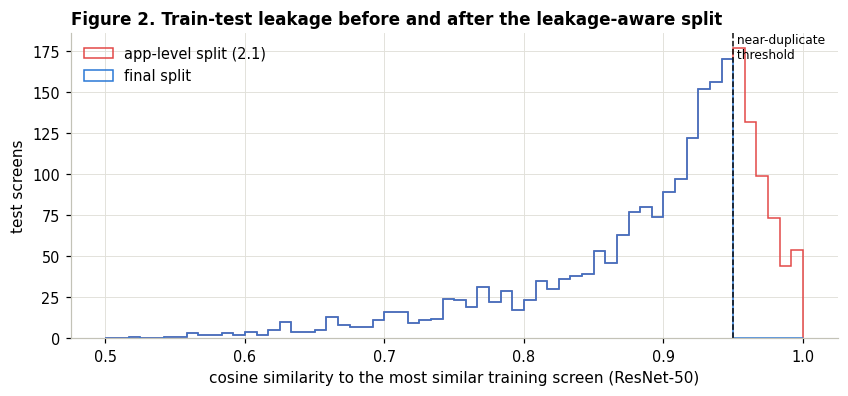

In [10]:
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

valid = img_ok.copy()
ev("screens_used", int(valid.sum()))
Fn = F.normalize(torch.tensor(FEATS["resnet50"], dtype=torch.float32, device=DEVICE), dim=-1).half()


def near_dup_pairs(Fn, t, block=2048):
    src, dst = [], []
    for a in range(0, len(Fn), block):
        s = Fn[a:a + block] @ Fn.T
        s[torch.arange(s.shape[0]), torch.arange(a, a + s.shape[0])] = -1
        i, j = torch.nonzero(s > t, as_tuple=True)
        keep = (i + a) < j; src.append((i[keep] + a).cpu().numpy()); dst.append(j[keep].cpu().numpy())
    return np.concatenate(src), np.concatenate(dst)


def max_sim_to(Fn, q_idx, ref_idx, block=4096):
    if len(q_idx) == 0 or len(ref_idx) == 0:
        return np.zeros(0, dtype=np.float32)
    out = []
    R = Fn[torch.as_tensor(ref_idx, device=DEVICE)]
    for a in range(0, len(q_idx), block):
        out.append((Fn[torch.as_tensor(q_idx[a:a + block], device=DEVICE)] @ R.T).max(1).values.float().cpu())
    return torch.cat(out).numpy()


src, dst = near_dup_pairs(Fn, CFG["NEAR_DUP_T"])
has_dup = np.zeros(N_SCREENS, bool); has_dup[src] = True; has_dup[dst] = True
ev("near_duplicate_pairs", len(src)); ev("screens_with_a_near_duplicate", has_dup.mean())
app_id = pd.factorize(meta_c["app_package_name"].fillna("NA"))[0]
ev("near_duplicate_pairs_across_apps", float((app_id[src] != app_id[dst]).mean()) if len(src) else 0.0)


def assign_groups(groups, fracs, seed, force_train=None):
    rng = np.random.default_rng(seed)
    uniq = rng.permutation(np.unique(groups)); sizes = pd.Series(groups).value_counts()
    target = {"test": fracs[2] * len(groups), "val": fracs[1] * len(groups)}; split_of = {}; filled = {"test": 0, "val": 0}
    for g in uniq:
        if force_train is not None and g == force_train:
            split_of[g] = "train"; continue
        for s in ["test", "val"]:
            if filled[s] + sizes[g] <= target[s] * 1.02:
                split_of[g] = s; filled[s] += sizes[g]; break
        else:
            split_of[g] = "train"
    return np.array([split_of[g] for g in groups], dtype=object)


def leakage(split):
    tr = np.where((split == "train") & valid)[0]; res = {}
    for s in ["val", "test"]:
        q = np.where((split == s) & valid)[0]
        res[s] = float((max_sim_to(Fn, q, tr) > CFG["NEAR_DUP_T"]).mean()) if len(q) else float("nan")
    return res


# (a) naive app-level split
split_app = assign_groups(app_id, CFG["SPLIT_FRACS"], CFG["SEED"])
ev("leakage_app_split_val_test", leakage(split_app))

# (b) components of the screen-app-duplicate graph
n_apps = app_id.max() + 1
rows_ = np.concatenate([np.arange(N_SCREENS), src]); cols_ = np.concatenate([N_SCREENS + app_id, dst])
graph = coo_matrix((np.ones(len(rows_)), (rows_, cols_)), shape=(N_SCREENS + n_apps,) * 2)
_, comp = connected_components(graph, directed=False); comp = comp[:N_SCREENS]
comp_sizes = pd.Series(comp).value_counts()
ev("n_components", len(comp_sizes)); ev("largest_component_share", comp_sizes.iloc[0] / N_SCREENS)

if comp_sizes.iloc[0] / N_SCREENS <= CFG["MAX_COMPONENT_SHARE"]:
    SPLIT_STRATEGY = "apps grouped by near-duplicate links (as proposed)"
    split = assign_groups(comp, CFG["SPLIT_FRACS"], CFG["SEED"], force_train=comp_sizes.index[0])
else:
    SPLIT_STRATEGY = "app-level split + purge of val/test screens with a train near-duplicate (fallback)"
    split = split_app.copy()
    tr = np.where((split == "train") & valid)[0]
    for s in ["val", "test"]:
        q = np.where((split == s) & valid)[0]
        leak = q[max_sim_to(Fn, q, tr) > CFG["NEAR_DUP_T"]]
        split[leak] = "purged"; ev(f"purged_{s}_screens", len(leak))
split[~valid] = "dropped"
assert all((split == s).sum() >= 20 for s in ["train", "val", "test"]), (
    "A split became (almost) empty after purging. Raise CFG['NEAR_DUP_T'] (e.g. 0.97) and re-run.")
meta_c["split"] = split
ev("split_strategy", SPLIT_STRATEGY); ev("leakage_final_split_val_test", leakage(split))
split_tbl = meta_c.groupby("split").agg(screens=("_row", "size"), apps=("app_package_name", "nunique"))
split_tbl["captions"] = [int(cap_cnt[split == s].sum()) for s in split_tbl.index]
print("Table 2: final split"); display(split_tbl); save_tbl(split_tbl, "t02_split")
ev("split_sizes", split_tbl["screens"].to_dict())
apps_by = {s: set(meta_c.loc[split == s, "app_package_name"]) for s in ["train", "val", "test"]}
ev("app_overlap_train_test", len(apps_by["train"] & apps_by["test"]))
tr_text = {cap_norm[c] for m in np.where(split == "train")[0] for c in range(cap_start[m], cap_start[m] + cap_cnt[m])}
te_caps = [cap_norm[c] for m in np.where(split == "test")[0] for c in range(cap_start[m], cap_start[m] + cap_cnt[m])]
ev("test_captions_with_identical_train_text", np.mean([c in tr_text for c in te_caps]))

# figure: nearest-train similarity of test screens, naive vs final
fig, ax = plt.subplots(figsize=(9, 3.6))
for spl, name, col in [(split_app, "app-level split (2.1)", C["red"]), (split, "final split", C["blue"])]:
    q = np.where((spl == "test") & valid)[0]; tr = np.where((spl == "train") & valid)[0]
    ax.hist(max_sim_to(Fn, q, tr), bins=60, range=(0.5, 1.0), histtype="step", lw=2, color=col, label=name)
ax.axvline(CFG["NEAR_DUP_T"], color=INK, ls="--", lw=1); ax.text(CFG["NEAR_DUP_T"], ax.get_ylim()[1] * 0.92, " near-duplicate\n threshold", fontsize=8)
ax.set(xlabel="cosine similarity to the most similar training screen (ResNet-50)", ylabel="test screens"); ax.legend(loc="upper left")
ax.set_title("Figure 2. Train-test leakage before and after the leakage-aware split", loc="left", fontweight="bold")
save_fig(fig, "fig02_leakage")
del Fn; torch.cuda.empty_cache() if DEVICE == "cuda" else None

## 6. Evaluation protocol and metrics
*i2t*: a screen query is correct if **any** of its captions is retrieved. *t2i*: a caption query is correct if its screen
is retrieved. Ties count half, so constant scorers cannot look good. Two variants:
* **strict**: only the annotated pairs are positives (standard protocol);
* **lenient**: a candidate with the *identical* caption text is also correct. Because 32% of captions are reused across
  screens ("login page"), strict scores penalise answers that are correct by construction. Proposal: "evaluation accepts
  multiple matches".

Metrics: Recall@1/5/10, MRR, median rank, both directions. Uncertainty: **cluster bootstrap** over screens (captions of
one screen are not independent), 95% percentile intervals, and paired bootstrap for differences between methods.

In [11]:
# Prepare normalised features for each split, identify matching image-caption pairs, calculate retrieval metrics, and
# estimate confidence intervals using cluster-based bootstrap sampling.

def to_dev(a, dtype=torch.float32): return torch.as_tensor(a, dtype=dtype, device=DEVICE)


def build_split(screens, img_key, txt_key, scalers):
    screens = np.asarray(screens)
    cap_ids = np.concatenate([np.arange(cap_start[m], cap_start[m] + cap_cnt[m]) for m in screens])
    cnt = cap_cnt[screens]
    XI = (FEATS[img_key][screens].astype(np.float32) - scalers[0][0]) / scalers[0][1]
    XT = (FEATS[txt_key][cap_ids].astype(np.float32) - scalers[1][0]) / scalers[1][1]
    return dict(XI=to_dev(XI), XT=to_dev(XT), cap2img=to_dev(np.repeat(np.arange(len(screens)), cnt), torch.long),
                start=to_dev(np.concatenate([[0], np.cumsum(cnt)[:-1]]), torch.long), cnt=to_dev(cnt, torch.long),
                tid=to_dev(cap_tid[cap_ids], torch.long), screens=screens, cap_ids=cap_ids)


SPLIT_IDX = {s: np.where(split == s)[0] for s in ["train", "val", "test"]}
SPLIT_IDX["train_sub"] = np.sort(np.random.default_rng(1).choice(SPLIT_IDX["train"], len(SPLIT_IDX["test"]), replace=False))


def make_data(img_key, txt_key):
    tr = SPLIT_IDX["train"]; tr_caps = np.concatenate([np.arange(cap_start[m], cap_start[m] + cap_cnt[m]) for m in tr])
    sc = lambda X: (X.astype(np.float32).mean(0, keepdims=True), X.astype(np.float32).std(0, keepdims=True) + 1e-6)
    scalers = (sc(FEATS[img_key][tr]), sc(FEATS[txt_key][tr_caps]))
    return {s: build_split(idx, img_key, txt_key, scalers) for s, idx in SPLIT_IDX.items()}


def pos_masks(d):
    n_img = len(d["screens"]); n_cap = len(d["cap2img"])
    strict = d["cap2img"][None, :] == torch.arange(n_img, device=DEVICE)[:, None]
    loc = torch.unique(d["tid"], return_inverse=True)[1]
    A = torch.zeros(n_img, int(loc.max()) + 1, dtype=torch.bool, device=DEVICE); A[d["cap2img"], loc] = True
    return strict, A[:, loc]


def ranks_rows(S, M, chunk=4096):
    out = []
    for a in range(0, S.shape[0], chunk):
        s, m = S[a:a + chunk].float(), M[a:a + chunk]
        best = s.masked_fill(~m, float("-inf")).max(1).values[:, None]
        out.append(1.0 + ((s > best) & ~m).sum(1).float() + 0.5 * ((s == best) & ~m).sum(1).float())
    return torch.cat(out)


def evaluate(S_i2t, d, S_t2i=None, lenient=True):
    S_t2i = S_i2t if S_t2i is None else S_t2i
    strict, len_m = d.get("_masks") or pos_masks(d); d["_masks"] = (strict, len_m)
    R = {"i2t": ranks_rows(S_i2t, strict), "t2i": ranks_rows(S_t2i.T, strict.T)}
    if lenient:
        R["i2t_len"] = ranks_rows(S_i2t, len_m); R["t2i_len"] = ranks_rows(S_t2i.T, len_m.T)
    m = {}
    for k, r in R.items():
        for K in [1, 5, 10]:
            m[f"{k}_R{K}"] = (r <= K).float().mean().item() * 100
        m[f"{k}_MRR"] = (1 / r).mean().item(); m[f"{k}_MedR"] = r.median().item()
    m["avg_R10"] = (m["i2t_R10"] + m["t2i_R10"]) / 2; m["avg_R1"] = (m["i2t_R1"] + m["t2i_R1"]) / 2
    m["rsum"] = sum(m[f"{k}_R{K}"] for k in ["i2t", "t2i"] for K in [1, 5, 10])
    return m, {k: v.cpu().numpy() for k, v in R.items()}


def cluster_boot(values, cluster, reps=None, seed=0):
    reps = reps or CFG["BOOT_REPS"]; rng = np.random.default_rng(seed)
    n = cluster.max() + 1; sums = np.bincount(cluster, values, n); cnts = np.bincount(cluster, minlength=n)
    idx = rng.integers(0, n, (reps, n))
    est = sums[idx].sum(1) / np.maximum(cnts[idx].sum(1), 1)
    return np.percentile(est, [2.5, 97.5])


def clusters(d, direction):
    return np.arange(len(d["screens"])) if direction.startswith("i2t") else d["cap2img"].cpu().numpy()

## 7. Models
* **Ridge**: closed-form linear map from standardised text features to image features; cosine ranking both ways.
* **Early fusion**: each modality projected (Linear-GELU-Dropout), concatenated, then an MLP outputs one match logit.
  The first fusion layer acting on `[h_img ; h_txt]` equals `W_a h_img + W_b h_txt`, so all-pairs scoring is computed as
  a broadcast sum instead of materialising concatenated pairs. Same function, about 100x less work, which makes
  in-batch training over every screen-caption pair and full-gallery evaluation feasible on a T4.
* **Contrastive dual encoder**: separate projection heads into a 256-d L2-normalised space with a learnable temperature
  (Radford et al., 2021).

**Loss.** Symmetric InfoNCE (van den Oord et al., 2018) generalised to **multiple positives** (MIL-NCE, Miech et al., 2020):
every caption of a screen is a positive, and (`multi_dedup`) any other caption in the batch with identical text is also a
positive instead of a false negative. The same loss trains early fusion (`softmax`), so the two techniques differ only in
architecture; the 2.1 binary cross-entropy objective is kept as an ablation (`bce`).

In [12]:
# Define the dual-encoder and early-fusion models, along with Ridge regression and multi-positive contrastive loss.
# caption batches and positive-pair masks is prepared for training and image-text matching.

def proj(din, dout, head="mlp"):
    if head == "linear":
        return nn.Linear(din, dout)
    return nn.Sequential(nn.Linear(din, CFG["PROJ_HIDDEN"]), nn.GELU(), nn.Dropout(CFG["DROPOUT"]), nn.Linear(CFG["PROJ_HIDDEN"], dout))


class DualEncoder(nn.Module):
    def __init__(self, d_img, d_txt, head="mlp"):
        super().__init__()
        self.drop = nn.Dropout(CFG["INPUT_DROPOUT"])
        self.fi, self.ft = proj(d_img, CFG["PROJ_OUT"], head), proj(d_txt, CFG["PROJ_OUT"], head)
        self.logit_scale = nn.Parameter(torch.tensor(math.log(1 / 0.07)))
    def enc_i(self, x): return F.normalize(self.fi(self.drop(x)), dim=-1)
    def enc_t(self, x): return F.normalize(self.ft(self.drop(x)), dim=-1)
    def pair_logits(self, xi, xt): return self.logit_scale.exp().clamp(max=100) * self.enc_i(xi) @ self.enc_t(xt).T
    @torch.no_grad()
    def score_matrix(self, XI, XT):
        self.eval(); return self.enc_i(XI) @ self.enc_t(XT).T


class EarlyFusion(nn.Module):
    def __init__(self, d_img, d_txt, d=None):
        super().__init__()
        d = d or CFG["PROJ_HIDDEN"]; p = CFG["DROPOUT"]
        self.pi = nn.Sequential(nn.Dropout(CFG["INPUT_DROPOUT"]), nn.Linear(d_img, d), nn.GELU(), nn.Dropout(p))
        self.pt = nn.Sequential(nn.Dropout(CFG["INPUT_DROPOUT"]), nn.Linear(d_txt, d), nn.GELU(), nn.Dropout(p))
        self.wa, self.wb = nn.Linear(d, d), nn.Linear(d, d, bias=False)
        self.out = nn.Sequential(nn.GELU(), nn.Dropout(p), nn.Linear(d, 1))
    def forward(self, xi, xt):
        return self.out(self.wa(self.pi(xi)) + self.wb(self.pt(xt))).squeeze(-1)
    def pair_logits(self, xi, xt):
        a, b = self.wa(self.pi(xi)), self.wb(self.pt(xt))
        return self.out(a[:, None, :] + b[None, :, :]).squeeze(-1)
    @torch.no_grad()
    def score_matrix(self, XI, XT, budget=1.5e8):
        self.eval(); a, b = self.wa(self.pi(XI)), self.wb(self.pt(XT))
        chunk = max(1, int(budget // (b.shape[0] * b.shape[1]))); rows = []
        with amp():
            for s in range(0, a.shape[0], chunk):
                rows.append(self.out(a[s:s + chunk, None, :] + b[None]).squeeze(-1).float())
        return torch.cat(rows)


def ridge_fit(XT, Y, alpha):
    A = XT.double()
    return torch.linalg.solve(A.T @ A + alpha * torch.eye(A.shape[1], device=DEVICE, dtype=A.dtype), A.T @ Y.double()).float()


def ridge_scores(W, d):
    return F.normalize(d["XI"], dim=-1) @ F.normalize(d["XT"] @ W, dim=-1).T


def multi_pos_nce(logits, P):
    logits = logits.float()
    l_i = -(torch.logsumexp(logits.masked_fill(~P, float("-inf")), 1) - torch.logsumexp(logits, 1)).mean()
    l_t = -(torch.logsumexp(logits.T.masked_fill(~P.T, float("-inf")), 1) - torch.logsumexp(logits.T, 1)).mean()
    return 0.5 * (l_i + l_t)


def make_batch(d, idx, mode):
    B = len(idx); cnt = d["cnt"][idx]
    if mode == "single":
        cap_idx = d["start"][idx] + (torch.rand(B, device=DEVICE) * cnt).long(); owner = torch.arange(B, device=DEVICE)
    else:
        owner = torch.repeat_interleave(torch.arange(B, device=DEVICE), cnt)
        offs = torch.arange(len(owner), device=DEVICE) - torch.repeat_interleave(torch.cumsum(cnt, 0) - cnt, cnt)
        cap_idx = d["start"][idx][owner] + offs
    P = owner[None, :] == torch.arange(B, device=DEVICE)[:, None]
    if mode == "multi_dedup":
        tid = d["tid"][cap_idx]
        P = (P.float() @ (tid[:, None] == tid[None, :]).float()) > 0
    return cap_idx, P

## 8. Training loop
AdamW, weight decay 0.01, dropout 0.3 plus 0.1 input-feature dropout (feature-level augmentation, since pixels are not
revisited), early stopping on validation average Recall@10 with patience 8, best checkpoint restored. At every epoch the
same metric is computed on a training subset of the same gallery size as the test set, so the train-validation gap
measures overfitting rather than gallery-size effects. Test data is touched once, after training.

In [13]:
def batch_loss(model, kind, d, idx, loss_mode, ef_loss):
    if kind == "early" and ef_loss == "bce":
        cap_idx, _ = make_batch(d, idx, "single"); xi, xt = d["XI"][idx], d["XT"][cap_idx]
        pos = model(xi, xt)
        negs = torch.stack([model(xi, xt.roll(k, 0)) for k in range(1, min(7, len(idx) - 1) + 1)])
        return F.binary_cross_entropy_with_logits(pos, torch.ones_like(pos)) + F.binary_cross_entropy_with_logits(negs, torch.zeros_like(negs))
    cap_idx, P = make_batch(d, idx, loss_mode)
    return multi_pos_nce(model.pair_logits(d["XI"][idx], d["XT"][cap_idx]), P)


def train(kind, D, seed, loss_mode="multi_dedup", ef_loss="softmax", head="mlp", verbose=False, sample_weights=None):
    seed_everything(seed)
    tr, va = D["train"], D["val"]
    model = (EarlyFusion if kind == "early" else DualEncoder)(tr["XI"].shape[1], tr["XT"].shape[1], **({"head": head} if kind != "early" else {})).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=CFG["LR"], weight_decay=CFG["WD"])
    bs = CFG["BATCH_SCREENS_EF"] if kind == "early" else CFG["BATCH_SCREENS"]
    n = tr["XI"].shape[0]; hist = []; best = dict(score=-1, state=None, epoch=0); bad = 0
    g_val = torch.Generator(device="cpu").manual_seed(0)
    val_batches = [torch.randperm(len(va["screens"]), generator=g_val)[i:i + bs].to(DEVICE) for i in range(0, min(len(va["screens"]), 4 * bs), bs)]
    gpu_reset(); t0 = time.perf_counter()
    for ep in range(1, CFG["EPOCHS"] + 1):
        model.train(); perm = torch.randperm(n, device=DEVICE); losses = []
        for b in range(0, n, bs):
            idx = perm[b:b + bs] if sample_weights is None else torch.multinomial(sample_weights, min(bs, n), replacement=False)
            if len(idx) < 8: continue
            with amp():
                loss = batch_loss(model, kind, tr, idx, loss_mode, ef_loss)
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); losses.append(loss.item())
        model.eval()
        with torch.no_grad():
            with amp():
                vloss = float(np.mean([batch_loss(model, kind, va, i, loss_mode, ef_loss).item() for i in val_batches if len(i) >= 8]))
            mv, _ = evaluate(model.score_matrix(va["XI"], va["XT"]), va, lenient=False)
            mt, _ = evaluate(model.score_matrix(D["train_sub"]["XI"], D["train_sub"]["XT"]), D["train_sub"], lenient=False)
        hist.append(dict(epoch=ep, train_loss=np.mean(losses), val_loss=vloss, train_R10=mt["avg_R10"], val_R10=mv["avg_R10"]))
        if verbose: print(hist[-1])
        if mv["avg_R10"] > best["score"]:
            best = dict(score=mv["avg_R10"], state=copy.deepcopy(model.state_dict()), epoch=ep); bad = 0
        else:
            bad += 1
            if bad >= CFG["PATIENCE"]: break
    train_s = time.perf_counter() - t0
    model.load_state_dict(best["state"]); model.eval()
    return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best["epoch"], best_val=best["score"], train_s=train_s,
                peak_gb=gpu_peak_gb(), params=sum(p.numel() for p in model.parameters()))


def fit_ridge(D):
    rows = []
    Y = D["train"]["XI"][D["train"]["cap2img"]]
    for a in CFG["RIDGE_ALPHAS"]:
        W = ridge_fit(D["train"]["XT"], Y, a); m, _ = evaluate(ridge_scores(W, D["val"]), D["val"], lenient=False)
        rows.append(dict(alpha=a, val_avg_R10=m["avg_R10"]))
    tbl = pd.DataFrame(rows); a = float(tbl.sort_values("val_avg_R10").iloc[-1]["alpha"])
    with timer() as t:
        W = ridge_fit(D["train"]["XT"], Y, a)
    return W, a, tbl, t["s"]

## 9. Feature extractor selection (validation data only)
Ridge and the contrastive model (seed 0) are trained on every image encoder x BERT pooling combination. The combination
with the best validation average Recall@10 for the contrastive model is used for all later experiments.

In [14]:
sel_rows = []
for ik in IMG_KEYS:
    for tk in TXT_KEYS:
        D_ = make_data(ik, tk)
        _, a, rt, _ = fit_ridge(D_)
        r = train("contrastive", D_, 0)
        sel_rows.append(dict(image_encoder=ik, text_pooling=tk, img_dim=FEATS[ik].shape[1], ridge_val_avg_R10=rt["val_avg_R10"].max(),
                             contrastive_val_avg_R10=r["best_val"], contrastive_best_epoch=r["best_epoch"]))
        print(sel_rows[-1]); del D_, r; gc.collect()
sel = pd.DataFrame(sel_rows).sort_values("contrastive_val_avg_R10", ascending=False)
print("Table 3: feature extractor selection (validation, avg Recall@10 %)"); display(sel.round(2)); save_tbl(sel, "t03_feature_selection", index=False)
IMG_KEY, TXT_KEY = sel.iloc[0]["image_encoder"], sel.iloc[0]["text_pooling"]
ev("feature_selection", sel.round(2).to_dict("records")); ev("chosen_image_encoder", IMG_KEY); ev("chosen_text_pooling", TXT_KEY)
D = make_data(IMG_KEY, TXT_KEY)
ev("test_gallery", {"screens": len(D["test"]["screens"]), "captions": len(D["test"]["cap2img"])})

{'image_encoder': 'resnet50', 'text_pooling': 'bert_mean', 'img_dim': 2048, 'ridge_val_avg_R10': 8.795861899852753, 'contrastive_val_avg_R10': 12.63708509504795, 'contrastive_best_epoch': 12}
{'image_encoder': 'resnet50', 'text_pooling': 'bert_cls', 'img_dim': 2048, 'ridge_val_avg_R10': 7.97976553440094, 'contrastive_val_avg_R10': 11.489061266183853, 'contrastive_best_epoch': 12}
{'image_encoder': 'efficientnet_b0', 'text_pooling': 'bert_mean', 'img_dim': 1280, 'ridge_val_avg_R10': 9.001148492097855, 'contrastive_val_avg_R10': 14.691364020109177, 'contrastive_best_epoch': 10}
{'image_encoder': 'efficientnet_b0', 'text_pooling': 'bert_cls', 'img_dim': 1280, 'ridge_val_avg_R10': 8.128053322434425, 'contrastive_val_avg_R10': 13.70985172688961, 'contrastive_best_epoch': 10}
{'image_encoder': 'vit_b_16', 'text_pooling': 'bert_mean', 'img_dim': 768, 'ridge_val_avg_R10': 9.3128751963377, 'contrastive_val_avg_R10': 15.279996395111084, 'contrastive_best_epoch': 15}
{'image_encoder': 'vit_b_16',

,image_encoder,text_pooling,img_dim,ridge_val_avg_R10,contrastive_val_avg_R10,contrastive_best_epoch
4,vit_b_16,bert_mean,768,9.31,15.28,15
2,efficientnet_b0,bert_mean,1280,9.00,14.69,10
5,vit_b_16,bert_cls,768,8.62,14.10,17
3,efficientnet_b0,bert_cls,1280,8.13,13.71,10
0,resnet50,bert_mean,2048,8.80,12.64,12
1,resnet50,bert_cls,2048,7.98,11.49,12


[evidence] feature_selection = [{'image_encoder': 'vit_b_16', 'text_pooling': 'bert_mean', 'img_dim': 768, 'ridge_val_avg_R10': 9.31, 'contrastive_val_avg_R10': 15.28, 'contrastive_best_epoch': 15}, {'image_encoder': 'efficientnet_b0', 'text_pooling': 'bert_mean', 'img_dim': 1280, 'ridge_val_avg_R10': 9.0, 'contrastive_val_avg_R10': 14.69, 'contrastive_best_epoch': 10}, {'image_encoder': 'vit_b_16', 'text_pooling': 'bert_cls', 'img_dim': 768, 'ridge_val_avg_R10': 8.62, 'contrastive_val_avg_R10': 14.1, 'contrastive_best_epoch': 17}, {'image_encoder': 'efficientnet_b0', 'text_pooling': 'bert_cls', 'img_dim': 1280, 'ridge_val_avg_R10': 8.13, 'contrastive_val_avg_R10': 13.71, 'contrastive_best_epoch': 10}, {'image_encoder': 'resnet50', 'text_pooling': 'bert_mean', 'img_dim': 2048, 'ridge_val_avg_R10': 8.8, 'contrastive_val_avg_R10': 12.64, 'contrastive_best_epoch': 12}, {'image_encoder': 'resnet50', 'text_pooling': 'bert_cls', 'img_dim': 2048, 'ridge_val_avg_R10': 7.98, 'contrastive_val_av

## 10. Main experiments (3 seeds each)

In [15]:
RESULTS = {}      # name -> list of per-seed dicts with test metrics and per-query ranks
SMAT = {}         # name -> (i2t score matrix, t2i score matrix) of the first seed, for failure analysis


def record(name, S_i2t, d, extra=None, S_t2i=None, seed=0):
    m, r = evaluate(S_i2t, d, S_t2i)
    RESULTS.setdefault(name, []).append(dict(seed=seed, test=m, ranks=r, **(extra or {})))
    if name not in SMAT:
        SMAT[name] = (S_i2t.half(), (S_i2t if S_t2i is None else S_t2i).half())
    return m


# random baseline
for s in CFG["SEEDS"]:
    g = torch.Generator(device="cpu").manual_seed(s)
    record("Random", torch.rand(len(D["test"]["screens"]), len(D["test"]["cap2img"]), generator=g).to(DEVICE), D["test"], seed=s)

# ridge (deterministic, one run)
W_ridge, RIDGE_ALPHA, ridge_tbl, ridge_s = fit_ridge(D)
display(ridge_tbl.round(2)); ev("ridge_alpha", RIDGE_ALPHA)
m_tr, _ = evaluate(ridge_scores(W_ridge, D["train_sub"]), D["train_sub"], lenient=False)
m_va, _ = evaluate(ridge_scores(W_ridge, D["val"]), D["val"], lenient=False)
record("Ridge", ridge_scores(W_ridge, D["test"]), D["test"], dict(train_s=ridge_s, params=W_ridge.numel(), train_sub=m_tr, val=m_va))

# early fusion and contrastive
MODELS = {}
for kind, name in [("early", "Early fusion"), ("contrastive", "Contrastive")]:
    for s in CFG["SEEDS"]:
        r = train(kind, D, s)
        m_tr, _ = evaluate(r["model"].score_matrix(D["train_sub"]["XI"], D["train_sub"]["XT"]), D["train_sub"], lenient=False)
        m_va, _ = evaluate(r["model"].score_matrix(D["val"]["XI"], D["val"]["XT"]), D["val"], lenient=False)
        S_te = r["model"].score_matrix(D["test"]["XI"], D["test"]["XT"])
        m = record(name, S_te, D["test"], dict(train_s=r["train_s"], params=r["params"], peak_gb=r["peak_gb"], best_epoch=r["best_epoch"],
                                                  hist=r["hist"], train_sub=m_tr, val=m_va), seed=s)
        MODELS[(name, s)] = r["model"]
        print(f"{name:13s} seed {s}: epoch {r['best_epoch']:2d}  val {r['best_val']:.1f}  test avg R@10 {m['avg_R10']:.1f}  ({r['train_s']:.0f}s)")

,alpha,val_avg_R10
0,100.0,9.27
1,1000.0,9.31
2,3000.0,9.16
3,10000.0,9.00
4,30000.0,8.62
5,100000.0,7.81
6,300000.0,7.07


[evidence] ridge_alpha = 1000.0
Early fusion  seed 0: epoch 22  val 15.0  test avg R@10 15.2  (82s)
Early fusion  seed 1: epoch 17  val 15.2  test avg R@10 14.9  (71s)
Early fusion  seed 2: epoch 17  val 14.7  test avg R@10 14.4  (70s)
Contrastive   seed 0: epoch 15  val 15.3  test avg R@10 15.3  (11s)
Contrastive   seed 1: epoch 25  val 15.4  test avg R@10 15.1  (16s)
Contrastive   seed 2: epoch 19  val 15.3  test avg R@10 14.6  (13s)


### 10.1 Hybrid: contrastive shortlist, early-fusion re-rank
For each query the contrastive model keeps its top-K candidates (K = 50); inside the shortlist the score is
`z(contrastive) + lambda * z(early fusion)` (z-scored per query). Lambda is chosen on validation data; candidates
outside the shortlist keep their contrastive order below it.

In [16]:
def zs(x): return (x - x.mean(1, keepdim=True)) / (x.std(1, keepdim=True) + 1e-6)

# Top-K candidates of the contrastive model for every query in both directions.
def shortlist(S_c, K):
    ti = S_c.topk(min(K, S_c.shape[1]), dim=1).indices
    tt = S_c.T.topk(min(K, S_c.shape[0]), dim=1).indices
    return ti, tt

# Re-rank the contrastive top-K with a second scorer. pair_scores(img_idx, cap_idx) -> scores (1-D).
def rerank(S_c, pair_scores, lam, K, sl=None):
    ti, tt = sl or shortlist(S_c, K); out = []
    for Q, top, i2t in [(S_c, ti, True), (S_c.T, tt, False)]:
        q = torch.arange(Q.shape[0], device=DEVICE)[:, None].expand_as(top)
        img, cap = (q, top) if i2t else (top, q)
        s2 = pair_scores(img.reshape(-1), cap.reshape(-1)).view_as(top).float()
        zc = zs(Q.gather(1, top).float()); z2 = zs(s2)
        comb = z2 + 1e-3 * zc if lam is None else zc + lam * z2
        H = Q.float().clone() - 1e4; H.scatter_(1, top, 1e4 + comb); out.append(H if i2t else H.T)
    return out[0], out[1]


def hybrid_scores(S_c, S_e, lam, K):
    return rerank(S_c, lambda i, c: S_e[i, c], lam, K)


hyb_rows = []
for s in CFG["SEEDS"]:
    mc, me = MODELS[("Contrastive", s)], MODELS[("Early fusion", s)]
    Sc_v, Se_v = mc.score_matrix(D["val"]["XI"], D["val"]["XT"]), me.score_matrix(D["val"]["XI"], D["val"]["XT"])
    best = (-1, 0)
    for lam in CFG["HYBRID_LAMBDAS"]:
        Hi, Ht = hybrid_scores(Sc_v, Se_v, lam, CFG["HYBRID_K"]); mv, _ = evaluate(Hi, D["val"], Ht, lenient=False)
        hyb_rows.append(dict(seed=s, lam=lam, val_avg_R10=mv["avg_R10"])); best = max(best, (mv["avg_R10"], lam))
    Hi, Ht = hybrid_scores(mc.score_matrix(D["test"]["XI"], D["test"]["XT"]), me.score_matrix(D["test"]["XI"], D["test"]["XT"]), best[1], CFG["HYBRID_K"])
    record("Hybrid (contrastive + EF re-rank)", Hi, D["test"], dict(lam=best[1], val=dict(avg_R10=best[0])), S_t2i=Ht, seed=s)
hyb_tbl = pd.DataFrame(hyb_rows).pivot(index="lam", columns="seed", values="val_avg_R10")
print("Table 4: hybrid lambda tuning (validation avg R@10)"); display(hyb_tbl.round(2)); save_tbl(hyb_tbl, "t04_hybrid_lambda")
ev("hybrid_lambdas_chosen", [r["lam"] for r in RESULTS["Hybrid (contrastive + EF re-rank)"]])

Table 4: hybrid lambda tuning (validation avg R@10)


seed,0,1,2
lam,,,
0.00,15.28,15.35,15.30
0.25,15.68,15.64,15.92
0.50,16.00,15.56,16.16
1.00,16.28,15.94,16.28
2.00,16.36,16.75,16.25
4.00,16.29,16.63,16.28


[evidence] hybrid_lambdas_chosen = [2.0, 2.0, 1.0]


### 10.2 Intermediate fusion: cross-attention between caption tokens and screen regions
Pooled vectors discard *where* things are on a screen and *which* words matter. This model keeps both:
* screen tokens: ResNet-50 layer-4 map pooled to a 7 x 3 grid (21 region tokens, rows follow the tall screen layout),
  each with a learned position embedding;
* caption tokens: BERT last-layer states (up to 16 tokens) with a padding mask and position embeddings;
* 2 transformer blocks in which caption tokens attend to screen regions (multi-head cross-attention, 4 heads, then a
  feed-forward layer), masked mean over caption tokens, MLP -> one match logit.

Cross-attention must run once for every query-candidate pair, so, as in ALBEF (Li et al., 2021) and BLIP, it is used as a
**re-ranker** of the contrastive top-20. Training uses the same multi-positive in-batch softmax, but batches are built
from 16 anchor screens plus 3 visually similar screens each (nearest neighbours in the contrastive image space), so the
negatives look like the hard candidates the re-ranker sees at test time.

In [17]:
class XBlock(nn.Module):
    def __init__(self, d, heads, p):
        super().__init__()
        self.ln_q, self.ln_kv, self.ln2 = nn.LayerNorm(d), nn.LayerNorm(d), nn.LayerNorm(d)
        self.attn = nn.MultiheadAttention(d, heads, dropout=p, batch_first=True)
        self.ffn = nn.Sequential(nn.Linear(d, 2 * d), nn.GELU(), nn.Dropout(p), nn.Linear(2 * d, d))
        self.drop = nn.Dropout(p)
    def forward(self, t, i):
        kv = self.ln_kv(i)
        t = t + self.drop(self.attn(self.ln_q(t), kv, kv, need_weights=False)[0])
        return t + self.drop(self.ffn(self.ln2(t)))


class CrossAttnFusion(nn.Module):
    def __init__(self, d_img, d_txt, n_reg, n_tok):
        super().__init__()
        d, p = CFG["XA_DIM"], CFG["XA_DROPOUT"]
        self.pi = nn.Sequential(nn.LayerNorm(d_img), nn.Linear(d_img, d)); self.pt = nn.Sequential(nn.LayerNorm(d_txt), nn.Linear(d_txt, d))
        self.pos_i = nn.Parameter(torch.randn(n_reg, d) * 0.02); self.pos_t = nn.Parameter(torch.randn(n_tok, d) * 0.02)
        self.blocks = nn.ModuleList([XBlock(d, CFG["XA_HEADS"], p) for _ in range(CFG["XA_LAYERS"])])
        self.head = nn.Sequential(nn.LayerNorm(d), nn.Linear(d, d), nn.GELU(), nn.Dropout(p), nn.Linear(d, 1))
    def embed(self, xi, xt):
        return self.pi(xi) + self.pos_i, self.pt(xt) + self.pos_t
    def fuse(self, hi, ht, m):
        for b in self.blocks:
            ht = b(ht, hi)
        m = m.unsqueeze(-1).to(ht.dtype)
        return self.head((ht * m).sum(1) / m.sum(1).clamp(min=1)).squeeze(-1)
    def pair_logits(self, xi, xt, m):
        hi, ht = self.embed(xi, xt); B, C = hi.shape[0], ht.shape[0]
        hi = hi[:, None].expand(B, C, *hi.shape[1:]).reshape(B * C, *hi.shape[1:])
        ht2 = ht[None].expand(B, C, *ht.shape[1:]).reshape(B * C, *ht.shape[1:])
        return self.fuse(hi, ht2, m[None].expand(B, C, -1).reshape(B * C, -1)).view(B, C)


if CFG["RUN_CROSS_ATTN"] and "img_regions" in TOKENS:
    def to_gpu_chunked(arr, chunk=8192):
        t = torch.empty(arr.shape, dtype=torch.from_numpy(np.asarray(arr[:1])).dtype, device=DEVICE)
        for a in range(0, len(arr), chunk):
            t[a:a + chunk] = torch.from_numpy(np.ascontiguousarray(arr[a:a + chunk])).to(DEVICE)
        return t
    TOK_I = to_gpu_chunked(TOKENS["img_regions"])
    TOK_T = to_gpu_chunked(TOKENS["txt_tokens"])
    TOK_M = to_gpu_chunked(TOKENS["txt_mask"])
    print(f"RAM after moving token features to GPU: {ram_gb():.1f} GB")
    G_SCR = {k: to_dev(v["screens"], torch.long) for k, v in D.items()}; G_CAP = {k: to_dev(v["cap_ids"], torch.long) for k, v in D.items()}

    def xa_pair_fn(model, split_name, chunk=4096):
        @torch.no_grad()
        def f(img, cap):
            model.eval(); out = []
            for a in range(0, len(img), chunk):
                gi, gc_ = G_SCR[split_name][img[a:a + chunk]], G_CAP[split_name][cap[a:a + chunk]]
                with amp():
                    hi, ht = model.embed(TOK_I[gi].float(), TOK_T[gc_].float())
                    out.append(model.fuse(hi, ht, TOK_M[gc_]).float())
            return torch.cat(out)
        return f

    def train_xattn(seed, con_model):
        seed_everything(seed); tr = D["train"]
        model = CrossAttnFusion(TOK_I.shape[-1], TOK_T.shape[-1], TOK_I.shape[1], TOK_T.shape[1]).to(DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=CFG["XA_LR"], weight_decay=CFG["WD"])
        with torch.no_grad():
            con_model.eval(); E = con_model.enc_i(tr["XI"]); nbr = []
            for a in range(0, len(E), 4096):
                sim = E[a:a + 4096] @ E.T; sim[torch.arange(sim.shape[0]), torch.arange(a, a + sim.shape[0])] = -2
                nbr.append(sim.topk(CFG["XA_NEIGHBOURS"] * 3, dim=1).indices)
            nbr = torch.cat(nbr)
        SL = {k: shortlist(con_model.score_matrix(D[k]["XI"], D[k]["XT"]), CFG["XA_K"]) for k in ["val", "train_sub"]}
        Sc = {k: con_model.score_matrix(D[k]["XI"], D[k]["XT"]) for k in ["val", "train_sub"]}
        n = len(tr["screens"]); A = CFG["XA_ANCHORS"]; hist = []; best = dict(score=-1, state=None, epoch=0); bad = 0
        gpu_reset(); t0 = time.perf_counter()
        for ep in range(1, CFG["XA_EPOCHS"] + 1):
            model.train(); perm = torch.randperm(n, device=DEVICE); losses = []
            for b in range(0, n, A):
                anc = perm[b:b + A]
                pick = torch.randint(0, nbr.shape[1], (len(anc), CFG["XA_NEIGHBOURS"]), device=DEVICE)
                idx = torch.unique(torch.cat([anc, nbr[anc].gather(1, pick).reshape(-1)]))
                if len(idx) < 4: continue
                cap_idx, _ = make_batch(tr, idx, "single"); tid = tr["tid"][cap_idx]
                P = torch.eye(len(idx), dtype=torch.bool, device=DEVICE) | (tid[:, None] == tid[None, :])
                gi, gc_ = G_SCR["train"][idx], G_CAP["train"][cap_idx]
                with amp():
                    loss = multi_pos_nce(model.pair_logits(TOK_I[gi].float(), TOK_T[gc_].float(), TOK_M[gc_]), P)
                opt.zero_grad(set_to_none=True); loss.backward(); opt.step(); losses.append(loss.item())
            Hi, Ht = rerank(Sc["val"], xa_pair_fn(model, "val"), None, CFG["XA_K"], SL["val"]); mv, _ = evaluate(Hi, D["val"], Ht, lenient=False)
            Hi, Ht = rerank(Sc["train_sub"], xa_pair_fn(model, "train_sub"), None, CFG["XA_K"], SL["train_sub"]); mt, _ = evaluate(Hi, D["train_sub"], Ht, lenient=False)
            hist.append(dict(epoch=ep, train_loss=np.mean(losses), train_R10=mt["avg_R10"], val_R10=mv["avg_R10"]))
            print(f"  cross-attn seed {seed} epoch {ep}: loss {hist[-1]['train_loss']:.3f}  val R@10 {mv['avg_R10']:.2f}  train-sub R@10 {mt['avg_R10']:.2f}")
            if mv["avg_R10"] > best["score"]:
                best = dict(score=mv["avg_R10"], state=copy.deepcopy(model.state_dict()), epoch=ep, train_sub=mt, val=mv); bad = 0
            else:
                bad += 1
                if bad >= CFG["XA_PATIENCE"]: break
        train_s = time.perf_counter() - t0; model.load_state_dict(best["state"]); model.eval()
        return dict(model=model, hist=pd.DataFrame(hist), best_epoch=best["epoch"], train_s=train_s, peak_gb=gpu_peak_gb(),
                    params=sum(p.numel() for p in model.parameters()), train_sub=best["train_sub"], val=best["val"], Sc_val=Sc["val"], SL_val=SL["val"])

    xa_rows = []
    for s in CFG["SEEDS"]:
        mc = MODELS[("Contrastive", s)]; r = train_xattn(s, mc); MODELS[("Cross-attention", s)] = r["model"]
        best = (-1, None)
        for lam in CFG["XA_LAMBDAS"]:
            Hi, Ht = rerank(r["Sc_val"], xa_pair_fn(r["model"], "val"), lam, CFG["XA_K"], r["SL_val"]); mv, _ = evaluate(Hi, D["val"], Ht, lenient=False)
            xa_rows.append(dict(seed=s, lam=str(lam), val_avg_R10=mv["avg_R10"]))
            if mv["avg_R10"] > best[0]: best = (mv["avg_R10"], lam)
        S_te = mc.score_matrix(D["test"]["XI"], D["test"]["XT"])
        with timer() as t_rr:
            Hi, Ht = rerank(S_te, xa_pair_fn(r["model"], "test"), best[1], CFG["XA_K"])
        n_pairs = CFG["XA_K"] * (S_te.shape[0] + S_te.shape[1])
        m = record("Cross-attention re-rank", Hi, D["test"], dict(lam=best[1], train_s=r["train_s"], params=r["params"], peak_gb=r["peak_gb"],
                   best_epoch=r["best_epoch"], hist=r["hist"], train_sub=r["train_sub"], val=r["val"], pairs_per_s=n_pairs / t_rr["s"]), S_t2i=Ht, seed=s)
        print(f"Cross-attn    seed {s}: epoch {r['best_epoch']:2d}  lambda {best[1]}  test avg R@10 {m['avg_R10']:.1f}  ({r['train_s']:.0f}s)")
    xa_tbl = pd.DataFrame(xa_rows).pivot(index="lam", columns="seed", values="val_avg_R10")
    print("Table 4b: cross-attention re-rank weight (validation avg R@10; None = cross-attention order only)"); display(xa_tbl.round(2))
    save_tbl(xa_tbl, "t04b_xattn_lambda")
    ev("xattn_lambdas_chosen", [r["lam"] for r in RESULTS["Cross-attention re-rank"]])
    ev("xattn_pairs_per_s", np.mean([r["pairs_per_s"] for r in RESULTS["Cross-attention re-rank"]]))

RAM after moving token features to GPU: 6.5 GB
  cross-attn seed 0 epoch 1: loss 3.396  val R@10 14.49  train-sub R@10 40.26
  cross-attn seed 0 epoch 2: loss 2.997  val R@10 14.59  train-sub R@10 42.06
  cross-attn seed 0 epoch 3: loss 2.804  val R@10 14.81  train-sub R@10 43.22
  cross-attn seed 0 epoch 4: loss 2.670  val R@10 15.02  train-sub R@10 45.16
  cross-attn seed 0 epoch 5: loss 2.555  val R@10 14.65  train-sub R@10 46.95
  cross-attn seed 0 epoch 6: loss 2.466  val R@10 14.84  train-sub R@10 47.56
Cross-attn    seed 0: epoch  4  lambda 1.0  test avg R@10 15.7  (660s)
  cross-attn seed 1 epoch 1: loss 3.473  val R@10 14.26  train-sub R@10 47.69
  cross-attn seed 1 epoch 2: loss 3.034  val R@10 15.12  train-sub R@10 48.42
  cross-attn seed 1 epoch 3: loss 2.854  val R@10 14.90  train-sub R@10 50.36
  cross-attn seed 1 epoch 4: loss 2.719  val R@10 15.51  train-sub R@10 52.06
  cross-attn seed 1 epoch 5: loss 2.631  val R@10 15.56  train-sub R@10 53.57
  cross-attn seed 1 epoc

seed,0,1,2
lam,,,
0.5,15.71,15.91,15.61
1.0,15.76,16.31,15.59
2.0,15.47,16.14,15.15
4.0,15.34,15.94,14.75
None,15.02,15.56,14.37


[evidence] xattn_lambdas_chosen = [1.0, 1.0, 0.5]
[evidence] xattn_pairs_per_s = 59276.2712


### 10.3 CLIP references (not a main technique)
(i) zero-shot CLIP ViT-B/32 with no training on this data; (ii) frozen CLIP features with our contrastive head, which
separates the value of better pretrained features from the value of the fusion design.

In [18]:
if CFG["RUN_CLIP_REFERENCE"] and "clip_img" in FEATS:
    te = D["test"]
    Si = F.normalize(to_dev(FEATS["clip_img"][te["screens"]].astype(np.float32)), dim=-1)
    St = F.normalize(to_dev(FEATS["clip_txt"][te["cap_ids"]].astype(np.float32)), dim=-1)
    record("CLIP zero-shot (ref)", Si @ St.T, te)
    D_clip = make_data("clip_img", "clip_txt")
    for s in CFG["SEEDS"]:
        r = train("contrastive", D_clip, s)
        record("CLIP feats + contrastive head (ref)", r["model"].score_matrix(D_clip["test"]["XI"], D_clip["test"]["XT"]), D_clip["test"],
               dict(train_s=r["train_s"], params=r["params"], best_epoch=r["best_epoch"]), seed=s)
    del D_clip

## 11. Ablations (one factor at a time from the main contrastive configuration, 3 seeds)
* loss: single positive per screen (2.1 protocol) vs all five captions as positives vs + duplicate-text positives
* projection head: 2-layer MLP vs linear
* early fusion objective: in-batch softmax vs binary cross-entropy with 7 negatives (2.1)

In [19]:
ABL = []
def abl_entry(label, kind, **kw):
    for s in CFG["SEEDS"]:
        r = train(kind, D, s, **kw)
        m, _ = evaluate(r["model"].score_matrix(D["test"]["XI"], D["test"]["XT"]), D["test"])
        ABL.append(dict(config=label, seed=s, test_avg_R10=m["avg_R10"], test_i2t_R10=m["i2t_R10"], test_t2i_R10=m["t2i_R10"],
                        val_avg_R10=r["best_val"], best_epoch=r["best_epoch"], train_s=r["train_s"]))


if CFG["RUN_ABLATIONS"]:
    for name, kind in [("Contrastive", "contrastive"), ("Early fusion", "early")]:
        for rr in RESULTS[name]:
            ABL.append(dict(config=f"{name}: main (multi-positive + dedup, MLP)", seed=rr["seed"], test_avg_R10=rr["test"]["avg_R10"],
                            test_i2t_R10=rr["test"]["i2t_R10"], test_t2i_R10=rr["test"]["t2i_R10"], val_avg_R10=rr["val"]["avg_R10"],
                            best_epoch=rr["best_epoch"], train_s=rr["train_s"]))
    abl_entry("Contrastive: single positive (2.1)", "contrastive", loss_mode="single")
    abl_entry("Contrastive: multi-positive, no dedup", "contrastive", loss_mode="multi")
    abl_entry("Contrastive: linear head", "contrastive", head="linear")
    abl_entry("Early fusion: BCE, 7 negatives (2.1)", "early", ef_loss="bce", loss_mode="single")
abl = pd.DataFrame(ABL)
if len(abl):
    abl_sum = abl.groupby("config").agg(test_avg_R10=("test_avg_R10", "mean"), sd=("test_avg_R10", "std"), test_i2t_R10=("test_i2t_R10", "mean"),
                                        test_t2i_R10=("test_t2i_R10", "mean"), val_avg_R10=("val_avg_R10", "mean"),
                                        best_epoch=("best_epoch", "mean"), train_s=("train_s", "mean")).sort_index()
    print("Table 5: ablations (test, mean over seeds)"); display(abl_sum.round(2)); save_tbl(abl_sum, "t05_ablations")
    ev("ablations", abl_sum.round(2).reset_index().to_dict("records"))

Table 5: ablations (test, mean over seeds)


,test_avg_R10,sd,test_i2t_R10,test_t2i_R10,val_avg_R10,best_epoch,train_s
config,,,,,,,
Contrastive: linear head,12.99,0.28,14.22,11.76,13.67,14.00,8.85
"Contrastive: main (multi-positive + dedup, MLP)",15.04,0.36,15.95,14.12,15.32,19.67,13.18
"Contrastive: multi-positive, no dedup",15.09,0.66,16.13,14.06,15.79,15.67,10.86
Contrastive: single positive (2.1),13.85,0.36,14.49,13.21,14.16,13.67,9.39
"Early fusion: BCE, 7 negatives (2.1)",10.52,1.06,10.64,10.40,11.61,30.00,131.08
"Early fusion: main (multi-positive + dedup, MLP)",14.84,0.41,15.52,14.15,14.99,18.67,74.47


[evidence] ablations = [{'config': 'Contrastive: linear head', 'test_avg_R10': 12.99, 'sd': 0.28, 'test_i2t_R10': 14.22, 'test_t2i_R10': 11.76, 'val_avg_R10': 13.67, 'best_epoch': 14.0, 'train_s': 8.85}, {'config': 'Contrastive: main (multi-positive + dedup, MLP)', 'test_avg_R10': 15.04, 'sd': 0.36, 'test_i2t_R10': 15.95, 'test_t2i_R10': 14.12, 'val_avg_R10': 15.32, 'best_epoch': 19.67, 'train_s': 13.18}, {'config': 'Contrastive: multi-positive, no dedup', 'test_avg_R10': 15.09, 'sd': 0.66, 'test_i2t_R10': 16.13, 'test_t2i_R10': 14.06, 'val_avg_R10': 15.79, 'best_epoch': 15.67, 'train_s': 10.86}, {'config': 'Contrastive: single positive (2.1)', 'test_avg_R10': 13.85, 'sd': 0.36, 'test_i2t_R10': 14.49, 'test_t2i_R10': 13.21, 'val_avg_R10': 14.16, 'best_epoch': 13.67, 'train_s': 9.39}, {'config': 'Early fusion: BCE, 7 negatives (2.1)', 'test_avg_R10': 10.52, 'sd': 1.06, 'test_i2t_R10': 10.64, 'test_t2i_R10': 10.4, 'val_avg_R10': 11.61, 'best_epoch': 30.0, 'train_s': 131.08}, {'config': '

## 12. Results: metrics, confidence intervals, success criterion

Table 6: test results, strict protocol (Recall %, MRR 0-1, MedR rank; mean ± sd over seeds)


,seeds,i2t_R1,i2t_R5,i2t_R10,i2t_MRR,i2t_MedR,t2i_R1,t2i_R5,t2i_R10,t2i_MRR,t2i_MedR,rsum
method,,,,,,,,,,,,
Random,3,0.12,0.43 ± 0.10,0.62 ± 0.11,0.01 ± 0.00,1114.00 ± 11.22,0.05 ± 0.02,0.31 ± 0.08,0.54 ± 0.08,0.00 ± 0.00,850.67 ± 4.03,2.07 ± 0.37
Ridge,1,2.05,6.56,10.19,0.05,188.00,1.09,4.47,7.70,0.04,226.00,32.06
Early fusion,3,2.56 ± 0.22,9.67 ± 0.33,15.52 ± 0.34,0.07 ± 0.00,94.50 ± 2.12,2.65 ± 0.08,8.72 ± 0.22,14.15 ± 0.38,0.07 ± 0.00,102.67 ± 1.25,53.28 ± 0.68
Contrastive,3,2.95 ± 0.14,9.86 ± 0.29,15.95 ± 0.31,0.07 ± 0.00,96.83 ± 4.37,2.57 ± 0.13,8.71 ± 0.17,14.12 ± 0.29,0.07 ± 0.00,110.00 ± 2.94,54.17 ± 0.93
Hybrid (contrastive + EF re-rank),3,2.95 ± 0.19,11.42 ± 0.13,17.16 ± 0.13,0.08 ± 0.00,97.00 ± 4.02,2.84 ± 0.07,9.64 ± 0.41,15.26 ± 0.35,0.07 ± 0.00,110.17 ± 2.72,59.28 ± 1.10
Cross-attention re-rank,3,3.32 ± 0.07,10.33 ± 0.40,16.32 ± 0.29,0.08 ± 0.00,97.00 ± 4.02,2.77 ± 0.11,9.06 ± 0.19,14.66 ± 0.55,0.07 ± 0.00,110.17 ± 2.72,56.46 ± 1.32
CLIP zero-shot (ref),1,13.42,27.36,35.03,0.21,28.00,9.15,21.17,27.69,0.15,64.00,133.81
CLIP feats + contrastive head (ref),3,16.09 ± 0.32,36.16 ± 1.35,47.24 ± 0.86,0.26 ± 0.01,12.67 ± 0.47,10.78 ± 0.05,26.98 ± 0.38,36.60 ± 0.15,0.19 ± 0.00,24.67 ± 0.47,173.85 ± 2.75


Table 7: lenient protocol (identical caption text counts as correct)


,i2t_len_R1,i2t_len_R10,i2t_len_MRR,t2i_len_R1,t2i_len_R10,t2i_len_MRR
method,,,,,,
Random,0.16,1.13,0.01,0.10,1.10,0.01
Ridge,2.28,10.31,0.05,1.31,10.83,0.05
Early fusion,3.61,16.77,0.08,3.72,18.79,0.09
Contrastive,3.69,17.59,0.08,3.31,18.74,0.09
Hybrid (contrastive + EF re-rank),4.12,18.98,0.09,3.78,20.14,0.09
Cross-attention re-rank,4.16,17.97,0.09,3.78,19.47,0.09
CLIP zero-shot (ref),13.53,35.27,0.21,9.86,30.69,0.17
CLIP feats + contrastive head (ref),17.79,48.84,0.28,12.77,41.66,0.22


[evidence] best_learned_model = Hybrid (contrastive + EF re-rank)
[evidence] success_criterion_vs_ridge_R10 = {'i2t': {'delta_pts': 6.9713, 'ci': [5.291, 8.5145], 'meets_5pt': True, 'significant_gt_0': True}, 't2i': {'delta_pts': 7.5688, 'ci': [6.5093, 8.5895], 'meets_5pt': True, 'significant_gt_0': True}}
[evidence] SUCCESS_CRITERION_MET_BOTH_DIRECTIONS = True
[evidence] avg_R10_1k_gallery_seed0 = {'Ridge': 13.244, 'Early fusion': 20.2209, 'Contrastive': 21.0127}


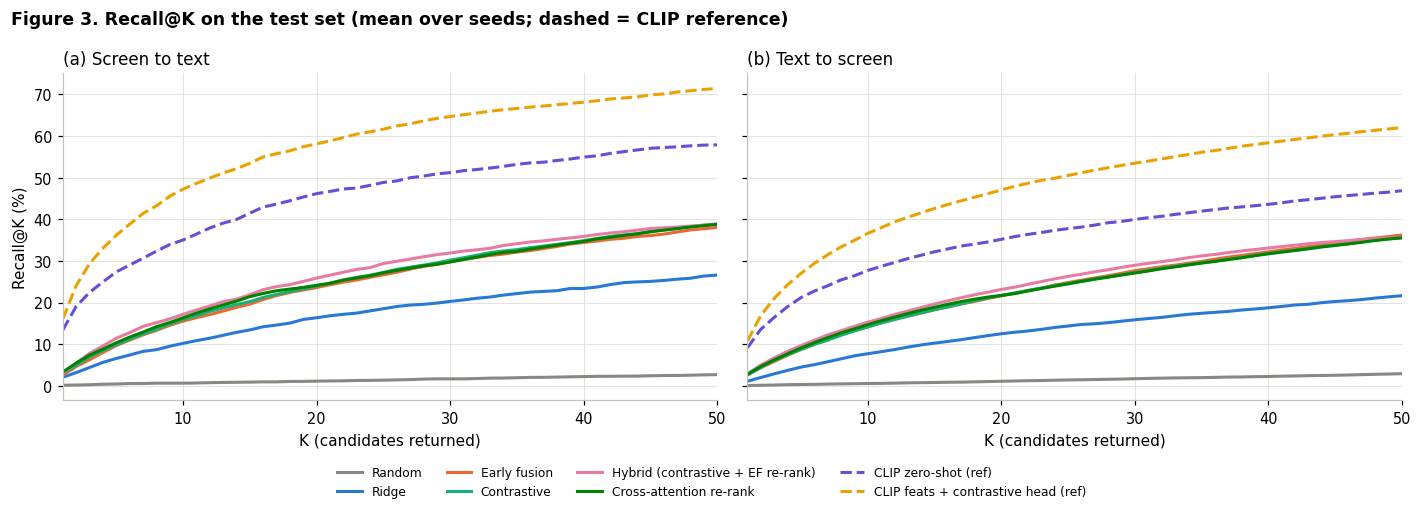

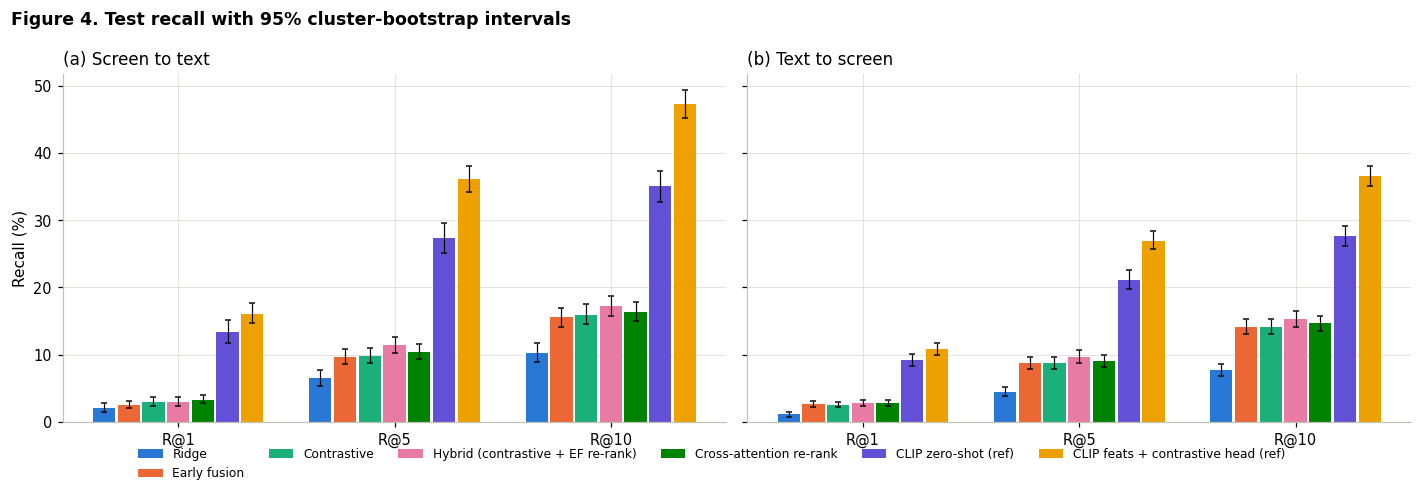

In [20]:
ORDER = [k for k in ["Random", "Ridge", "Early fusion", "Contrastive", "Hybrid (contrastive + EF re-rank)",
                     "Cross-attention re-rank", "CLIP zero-shot (ref)", "CLIP feats + contrastive head (ref)"] if k in RESULTS]
COLS = ["i2t_R1", "i2t_R5", "i2t_R10", "i2t_MRR", "i2t_MedR", "t2i_R1", "t2i_R5", "t2i_R10", "t2i_MRR", "t2i_MedR", "rsum"]
rows = []
for name in ORDER:
    df = pd.DataFrame([r["test"] for r in RESULTS[name]]); mu, sd = df.mean(), df.std(ddof=0)
    rows.append({"method": name, "seeds": len(df), **{c: (f"{mu[c]:.2f}" if len(df) == 1 or sd[c] == 0 else f"{mu[c]:.2f} ± {sd[c]:.2f}") for c in COLS}})
main_tbl = pd.DataFrame(rows).set_index("method")
print("Table 6: test results, strict protocol (Recall %, MRR 0-1, MedR rank; mean ± sd over seeds)"); display(main_tbl); save_tbl(main_tbl, "t06_main_results")
len_rows = []
for name in ORDER:
    df = pd.DataFrame([r["test"] for r in RESULTS[name]]).mean()
    len_rows.append({"method": name, **{f"{k}_{K}": round(df[f"{k}_{K}"], 2) for k in ["i2t_len", "t2i_len"] for K in ["R1", "R10", "MRR"]}})
len_tbl = pd.DataFrame(len_rows).set_index("method")
print("Table 7: lenient protocol (identical caption text counts as correct)"); display(len_tbl); save_tbl(len_tbl, "t07_lenient")
for name in ORDER:
    df = pd.DataFrame([r["test"] for r in RESULTS[name]]); ev(f"test::{name}", {c: df[c].mean() for c in COLS + ["avg_R10", "i2t_len_R10", "t2i_len_R10"]}, show=False)


# per-query hit rate averaged over seeds, then cluster bootstrap
def hits(name, direction, K):
    return np.mean([(r["ranks"][direction] <= K).astype(float) for r in RESULTS[name]], 0)


CI = {}
for name in ORDER:
    for dirn in ["i2t", "t2i"]:
        for K in [1, 5, 10]:
            h = hits(name, dirn, K); CI[(name, dirn, K)] = (h.mean() * 100, *(cluster_boot(h, clusters(D["test"], dirn)) * 100))
ci_tbl = pd.DataFrame([dict(method=n, direction=d, K=k, recall=v[0], ci_low=v[1], ci_high=v[2]) for (n, d, k), v in CI.items()])
save_tbl(ci_tbl, "t08_recall_ci", index=False)

# success criterion: best learned model vs ridge, paired cluster bootstrap on Recall@10
learned = [n for n in ["Early fusion", "Contrastive", "Hybrid (contrastive + EF re-rank)", "Cross-attention re-rank"] if n in RESULTS]
best_name = max(learned, key=lambda n: np.mean([r["test"]["avg_R10"] for r in RESULTS[n]]))
succ = {}
for dirn in ["i2t", "t2i"]:
    diff = hits(best_name, dirn, 10) - hits("Ridge", dirn, 10)
    lo, hi = cluster_boot(diff, clusters(D["test"], dirn)) * 100
    succ[dirn] = dict(delta_pts=diff.mean() * 100, ci=[lo, hi], meets_5pt=bool(diff.mean() * 100 >= CFG["SUCCESS_MARGIN"]),
                      significant_gt_0=bool(lo > 0))
ev("best_learned_model", best_name); ev("success_criterion_vs_ridge_R10", succ)
ev("SUCCESS_CRITERION_MET_BOTH_DIRECTIONS", all(v["meets_5pt"] for v in succ.values()))

# 1K-gallery protocol (folds of 1,000 test screens), comparable across papers
def fold_eval(name_to_S, d, size=1000, seed=0):
    perm = np.random.default_rng(seed).permutation(len(d["screens"])); out = {n: [] for n in name_to_S}
    for f in range(max(1, len(perm) // size)):
        im = np.sort(perm[f * size:(f + 1) * size]); caps = np.where(np.isin(d["cap2img"].cpu().numpy(), im))[0]
        sub = dict(screens=d["screens"][im], cap2img=to_dev(np.searchsorted(im, d["cap2img"].cpu().numpy()[caps]), torch.long),
                   tid=d["tid"][caps])
        for n, S_ in name_to_S.items():
            out[n].append(evaluate(S_[im][:, caps], sub, lenient=False)[0]["avg_R10"])
    return {n: float(np.mean(v)) for n, v in out.items()}


S0 = {"Ridge": ridge_scores(W_ridge, D["test"]), "Early fusion": MODELS[("Early fusion", 0)].score_matrix(D["test"]["XI"], D["test"]["XT"]),
      "Contrastive": MODELS[("Contrastive", 0)].score_matrix(D["test"]["XI"], D["test"]["XT"])}
ev("avg_R10_1k_gallery_seed0", fold_eval(S0, D["test"]))

# Figure 3: Recall@K curves; Figure 4: R@1/5/10 with 95% CIs
Ks = np.arange(1, 51)
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for j, (dirn, title) in enumerate([("i2t", "(a) Screen to text"), ("t2i", "(b) Text to screen")]):
    for name in ORDER:
        r = np.stack([res["ranks"][dirn] for res in RESULTS[name]])
        curve = [(r <= k).mean() * 100 for k in Ks]
        ax[j].plot(Ks, curve, color=METHOD_COLOR[name], lw=2, ls="--" if "(ref)" in name else "-", label=name)
    ax[j].set(xlabel="K (candidates returned)", xlim=(1, 50)); ax[j].set_title(title, loc="left")
ax[0].set_ylabel("Recall@K (%)")
h_, l_ = ax[1].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=4, fontsize=8, bbox_to_anchor=(0.5, -0.1))
fig.suptitle("Figure 3. Recall@K on the test set (mean over seeds; dashed = CLIP reference)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save_fig(fig, "fig03_recall_at_k")

fig, ax = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
show = [n for n in ORDER if n != "Random"]; w = 0.8 / len(show)
for j, dirn in enumerate(["i2t", "t2i"]):
    for i, name in enumerate(show):
        vals = [CI[(name, dirn, K)] for K in [1, 5, 10]]; x = np.arange(3) + (i - (len(show) - 1) / 2) * w
        ax[j].bar(x, [v[0] for v in vals], w * 0.9, color=METHOD_COLOR[name], label=name,
                  yerr=np.array([[v[0] - v[1] for v in vals], [v[2] - v[0] for v in vals]]), ecolor=INK, capsize=2, error_kw=dict(lw=0.8))
    ax[j].set_xticks(range(3)); ax[j].set_xticklabels(["R@1", "R@5", "R@10"])
    ax[j].set_title(["(a) Screen to text", "(b) Text to screen"][j], loc="left")
ax[0].set_ylabel("Recall (%)")
h_, l_ = ax[0].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=min(6, len(l_)), fontsize=8, bbox_to_anchor=(0.5, -0.06))
fig.suptitle("Figure 4. Test recall with 95% cluster-bootstrap intervals", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save_fig(fig, "fig04_recall_ci")

## 13. Overfitting assessment
Learning curves (loss and Recall@10 on equal-size train and validation galleries) and the train / validation / test gap
at the selected checkpoint for every trained method.

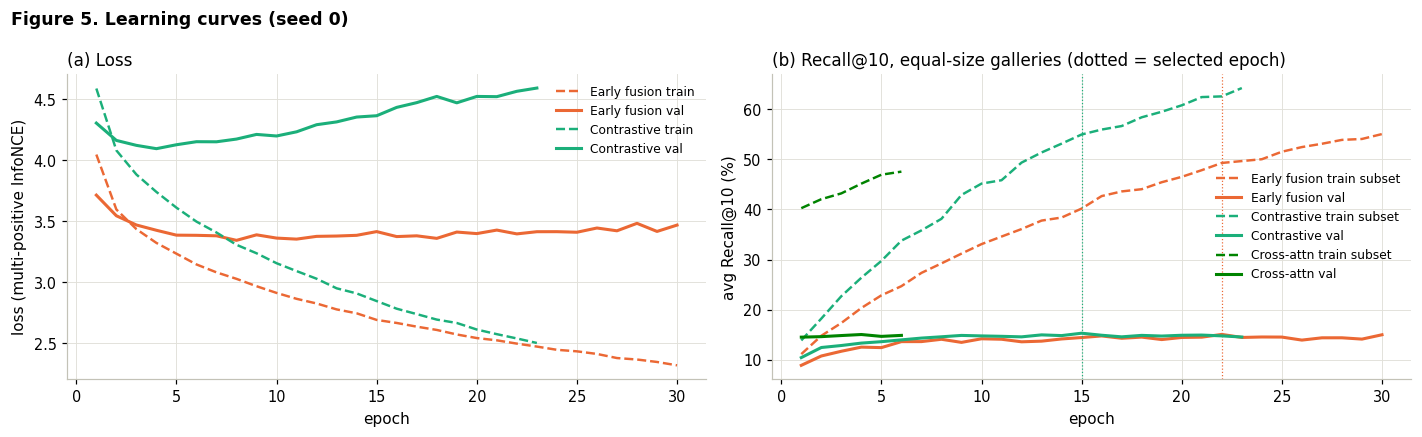

Table 9: overfitting check, avg Recall@10 (%) on equal-size galleries


,train_subset,val,test,gap_train_minus_test
method,,,,
Ridge,16.12,9.31,8.94,7.17
Early fusion,45.70,14.99,14.84,30.86
Contrastive,60.21,15.32,15.04,45.17
Cross-attention re-rank,48.22,14.98,15.49,32.73


[evidence] overfitting_avg_R10 = {'Ridge': {'train_subset': 16.12, 'val': 9.31, 'test': 8.94, 'gap_train_minus_test': 7.17}, 'Early fusion': {'train_subset': 45.7, 'val': 14.99, 'test': 14.84, 'gap_train_minus_test': 30.86}, 'Contrastive': {'train_subset': 60.21, 'val': 15.32, 'test': 15.04, 'gap_train_minus_test': 45.17}, 'Cross-attention re-rank': {'train_subset': 48.22, 'val': 14.98, 'test': 15.49, 'gap_train_minus_test': 32.73}}


In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for name in ["Early fusion", "Contrastive"]:
    h = RESULTS[name][0]["hist"]; col = METHOD_COLOR[name]; be = RESULTS[name][0]["best_epoch"]
    ax[0].plot(h.epoch, h.train_loss, color=col, ls="--", lw=1.6, label=f"{name} train"); ax[0].plot(h.epoch, h.val_loss, color=col, lw=2, label=f"{name} val")
    ax[1].plot(h.epoch, h.train_R10, color=col, ls="--", lw=1.6, label=f"{name} train subset"); ax[1].plot(h.epoch, h.val_R10, color=col, lw=2, label=f"{name} val")
    ax[1].axvline(be, color=col, lw=0.8, ls=":")
if "Cross-attention re-rank" in RESULTS:
    h = RESULTS["Cross-attention re-rank"][0]["hist"]; col = METHOD_COLOR["Cross-attention re-rank"]
    ax[1].plot(h.epoch, h.train_R10, color=col, ls="--", lw=1.6, label="Cross-attn train subset"); ax[1].plot(h.epoch, h.val_R10, color=col, lw=2, label="Cross-attn val")
ax[0].set(xlabel="epoch", ylabel="loss (multi-positive InfoNCE)"); ax[0].set_title("(a) Loss", loc="left"); ax[0].legend(fontsize=8)
ax[1].set(xlabel="epoch", ylabel="avg Recall@10 (%)"); ax[1].set_title("(b) Recall@10, equal-size galleries (dotted = selected epoch)", loc="left"); ax[1].legend(fontsize=8)
fig.suptitle("Figure 5. Learning curves (seed 0)", fontweight="bold", x=0.01, ha="left"); fig.tight_layout(); save_fig(fig, "fig05_learning_curves")

of_rows = []
for name in [n for n in ["Ridge", "Early fusion", "Contrastive", "Cross-attention re-rank"] if n in RESULTS]:
    rs = RESULTS[name]
    tr_ = np.mean([r["train_sub"]["avg_R10"] for r in rs]); va_ = np.mean([r["val"]["avg_R10"] for r in rs]); te_ = np.mean([r["test"]["avg_R10"] for r in rs])
    of_rows.append(dict(method=name, train_subset=tr_, val=va_, test=te_, gap_train_minus_test=tr_ - te_))
of_tbl = pd.DataFrame(of_rows).set_index("method")
print("Table 9: overfitting check, avg Recall@10 (%) on equal-size galleries"); display(of_tbl.round(2)); save_tbl(of_tbl, "t09_overfitting")
ev("overfitting_avg_R10", of_tbl.round(2).to_dict("index"))

## 14. Efficiency
Training cost per method, and ranking a query against a gallery of 1k to 1M candidates (measurable, not extrapolated). Early fusion must do its head on each query-candidate pair; the dual encoder embeds the gallery once, and in that one step only requires one matrix product; the hybrid includes early fusion on only K = 50 candidates. The report for the query encoding (BERT / ResNET forward pass) is done separately, as it is common to all methods.

Table 10: per-query ranking latency (ms, fp16, excludes query encoding)


,contrastive_ms,early_fusion_ms,hybrid_ms,cross_attn_rerank_ms,cross_attn_full_gallery_ms_extrapolated
gallery,,,,,
1000,0.076,0.109,0.142,0.414,16.870
10000,0.217,0.487,0.275,0.554,168.702
100000,0.450,3.314,0.514,0.787,1687.016
1000000,3.438,33.649,3.510,3.775,16870.157


[evidence] latency_ms = {'1000': {'contrastive_ms': 0.076, 'early_fusion_ms': 0.109, 'hybrid_ms': 0.142, 'cross_attn_rerank_ms': 0.414, 'cross_attn_full_gallery_ms_extrapolated': 16.87}, '10000': {'contrastive_ms': 0.217, 'early_fusion_ms': 0.487, 'hybrid_ms': 0.275, 'cross_attn_rerank_ms': 0.554, 'cross_attn_full_gallery_ms_extrapolated': 168.702}, '100000': {'contrastive_ms': 0.45, 'early_fusion_ms': 3.314, 'hybrid_ms': 0.514, 'cross_attn_rerank_ms': 0.787, 'cross_attn_full_gallery_ms_extrapolated': 1687.016}, '1000000': {'contrastive_ms': 3.438, 'early_fusion_ms': 33.649, 'hybrid_ms': 3.51, 'cross_attn_rerank_ms': 3.775, 'cross_attn_full_gallery_ms_extrapolated': 16870.157}}
[evidence] query_encoding_ms_per_caption_bert = 0.7252
Table 11: training cost


,params_M,train_s_mean,best_epoch_mean,peak_gpu_gb
method,,,,
Ridge,0.590,0.942,0.000,0.000
Early fusion,1.313,74.474,18.667,2.366
Contrastive,1.050,13.177,19.667,1.080
Cross-attention re-rank,1.858,661.152,4.000,8.600
CLIP feats + contrastive head (ref),0.788,14.456,23.000,0.000


[evidence] training_cost = {'Ridge': {'params_M': 0.59, 'train_s_mean': 0.942, 'best_epoch_mean': 0.0, 'peak_gpu_gb': 0.0}, 'Early fusion': {'params_M': 1.313, 'train_s_mean': 74.474, 'best_epoch_mean': 18.667, 'peak_gpu_gb': 2.366}, 'Contrastive': {'params_M': 1.05, 'train_s_mean': 13.177, 'best_epoch_mean': 19.667, 'peak_gpu_gb': 1.08}, 'Cross-attention re-rank': {'params_M': 1.858, 'train_s_mean': 661.152, 'best_epoch_mean': 4.0, 'peak_gpu_gb': 8.6}, 'CLIP feats + contrastive head (ref)': {'params_M': 0.788, 'train_s_mean': 14.456, 'best_epoch_mean': 23.0, 'peak_gpu_gb': 0.0}}


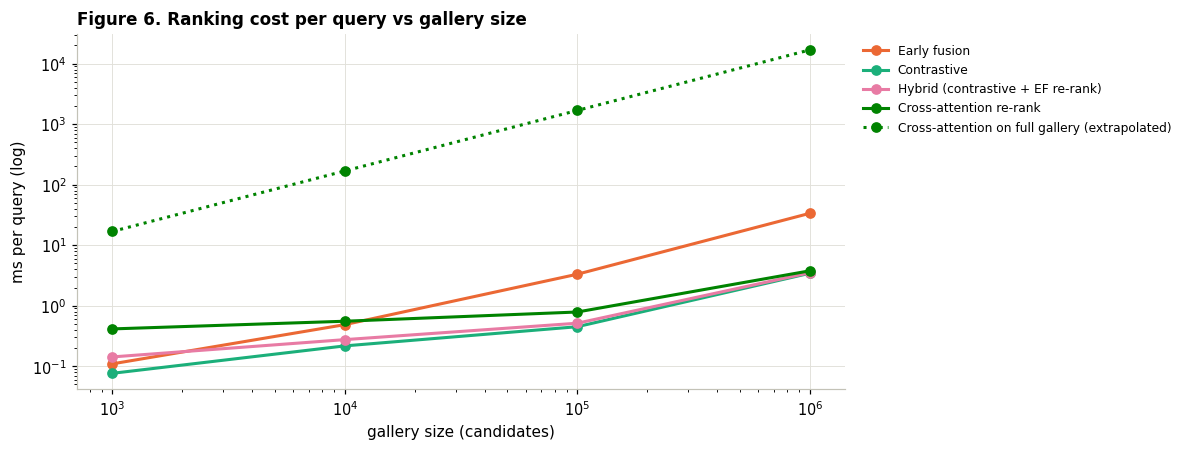

In [22]:
@torch.no_grad()
def latency_ms(fn, reps=5):
    fn()
    with timer() as t:
        for _ in range(reps): fn()
    return t["s"] / reps * 1000


m_c, m_e = MODELS[("Contrastive", 0)], MODELS[("Early fusion", 0)]
lat = []
for G in CFG["LATENCY_GALLERIES"]:
    row = dict(gallery=G)
    try:
        E = F.normalize(torch.randn(G, CFG["PROJ_OUT"], device=DEVICE), dim=-1).half(); q = F.normalize(torch.randn(1, CFG["PROJ_OUT"], device=DEVICE), dim=-1).half()
        row["contrastive_ms"] = latency_ms(lambda: (q @ E.T).topk(10)); del E
        d = CFG["PROJ_HIDDEN"]; Bg = torch.randn(G, d, device=DEVICE).half(); a = torch.randn(1, d, device=DEVICE).half()
        w2 = m_e.out[2].weight.half()
        def ef_query():
            for s0 in range(0, G, 250_000):
                (F.gelu(a + Bg[s0:s0 + 250_000]) @ w2.T).topk(min(10, Bg[s0:s0 + 250_000].shape[0]), dim=0)
        row["early_fusion_ms"] = latency_ms(ef_query)
        row["hybrid_ms"] = row["contrastive_ms"] + latency_ms(lambda: (F.gelu(a + Bg[:CFG["HYBRID_K"]]) @ w2.T))
        del Bg
    except RuntimeError as e:
        print("latency skipped at", G, repr(e)[:80])
    lat.append(row); torch.cuda.empty_cache() if DEVICE == "cuda" else None
lat_tbl = pd.DataFrame(lat).set_index("gallery")
if "Cross-attention re-rank" in RESULTS:
    pps = EVIDENCE["xattn_pairs_per_s"]
    lat_tbl["cross_attn_rerank_ms"] = lat_tbl["contrastive_ms"] + CFG["XA_K"] / pps * 1000
    lat_tbl["cross_attn_full_gallery_ms_extrapolated"] = lat_tbl.index / pps * 1000
print("Table 10: per-query ranking latency (ms, fp16, excludes query encoding)"); display(lat_tbl.round(3)); save_tbl(lat_tbl, "t10_latency")
ev("latency_ms", lat_tbl.round(3).to_dict("index"))
ev("query_encoding_ms_per_caption_bert", 1000 / (N_CAPS / TIMING["txt_s"]))

cost_rows = []
for name in [n for n in ["Ridge", "Early fusion", "Contrastive", "Cross-attention re-rank", "CLIP feats + contrastive head (ref)"] if n in RESULTS]:
    rs = RESULTS[name]
    cost_rows.append(dict(method=name, params_M=rs[0]["params"] / 1e6, train_s_mean=np.mean([r["train_s"] for r in rs]),
                          best_epoch_mean=np.mean([r.get("best_epoch", 0) for r in rs]), peak_gpu_gb=max(r.get("peak_gb", 0) for r in rs)))
cost_tbl = pd.DataFrame(cost_rows).set_index("method")
print("Table 11: training cost"); display(cost_tbl.round(3)); save_tbl(cost_tbl, "t11_training_cost")
ev("training_cost", cost_tbl.round(3).to_dict("index"))

fig, ax = plt.subplots(figsize=(9, 4.2))
for col, name, ls in [("early_fusion_ms", "Early fusion", "-"), ("contrastive_ms", "Contrastive", "-"), ("hybrid_ms", "Hybrid (contrastive + EF re-rank)", "-"),
                     ("cross_attn_rerank_ms", "Cross-attention re-rank", "-"), ("cross_attn_full_gallery_ms_extrapolated", "Cross-attention re-rank", ":")]:
    if col in lat_tbl:
        lab = name if ls == "-" else "Cross-attention on full gallery (extrapolated)"
        ax.plot(lat_tbl.index, lat_tbl[col], marker="o", ms=6, lw=2, ls=ls, color=METHOD_COLOR[name], label=lab)
ax.set(xscale="log", yscale="log", xlabel="gallery size (candidates)", ylabel="ms per query (log)")
ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.set_title("Figure 6. Ranking cost per query vs gallery size", loc="left", fontweight="bold")
save_fig(fig, "fig06_latency")

## 15. Bias and failure analysis
### 15.1 Performance by app category and for sensitive screen types

Table 12: Recall@10 by category (Hybrid (contrastive + EF re-rank), categories with >= 20 test screens)


,test_screens,train_screens,t2i_R10,ci_low,ci_high,i2t_R10,generic_caption_share
category,,,,,,,
Dating,41,257,5.9,2.3,10.8,8.1,0.3
Communication,139,1274,9.7,7.0,12.9,12.0,0.3
Books & Reference,66,778,11.7,7.1,16.9,10.6,0.3
Education,75,1088,12.0,7.4,16.7,16.9,0.2
Finance,95,680,12.6,8.2,16.7,16.8,0.3
Entertainment,124,1206,12.7,8.9,16.7,13.7,0.3
Social,91,1302,13.5,8.9,19.3,15.0,0.3
Music & Audio,74,636,13.6,9.5,18.1,14.0,0.3
Health & Fitness,120,1124,13.7,9.9,17.7,13.6,0.3


[evidence] category_t2i_R10_macro = 16.0522
[evidence] category_t2i_R10_micro = 15.2638
[evidence] category_t2i_R10_worst_best = {'Dating': 5.9113, 'Food & Drink': 28.0079}
[evidence] category_ci_overlap_worst_best = False
[evidence] spearman_train_size_vs_R10 = -0.3646
[evidence] spearman_generic_share_vs_R10 = -0.0939
[evidence] sensitive_vs_other_t2i_R10 = {'sensitive': 12.9927, 'other': 15.9665}
[evidence] sensitive_vs_other_t2i_len_R10 = {'sensitive': 22.3447, 'other': 19.4543}


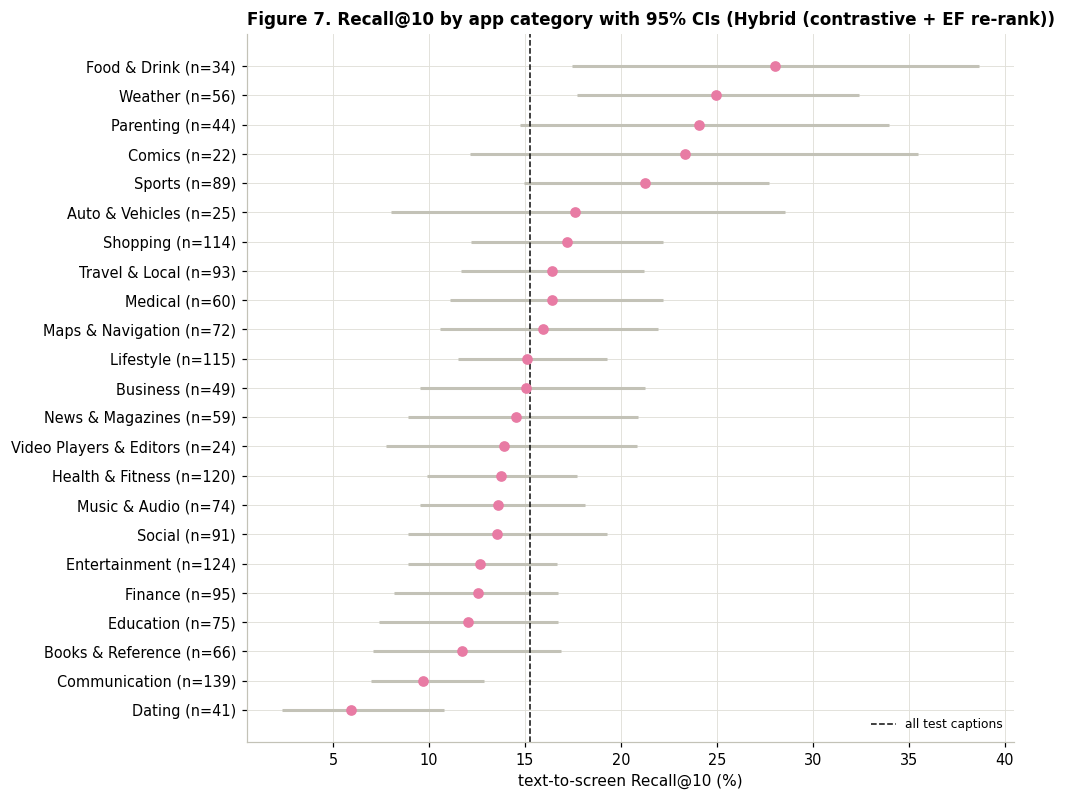

In [23]:
best_runs = RESULTS[best_name]; te = D["test"]
cat_img = meta_c["category_clean"].values[te["screens"]]; cat_cap = cat_img[te["cap2img"].cpu().numpy()]
sens_img = meta_c["sensitive"].values[te["screens"]]
h_t2i, h_i2t = hits(best_name, "t2i", 10), hits(best_name, "i2t", 10)
cl_t2i = te["cap2img"].cpu().numpy()
cat_rows = []
for c in pd.unique(cat_img):
    n_s = int((cat_img == c).sum())
    if n_s < CFG["MIN_CAT_SCREENS"] or c == "Unknown": continue
    mc_ = cat_cap == c; lo, hi = cluster_boot(h_t2i[mc_], pd.factorize(cl_t2i[mc_])[0]) * 100
    cat_rows.append(dict(category=c, test_screens=n_s, train_screens=int(((meta_c["category_clean"] == c) & (split == "train")).sum()),
                         t2i_R10=h_t2i[mc_].mean() * 100, ci_low=lo, ci_high=hi, i2t_R10=h_i2t[cat_img == c].mean() * 100,
                         generic_caption_share=float((cap_generic[te["cap_ids"]][mc_] > 1).mean())))
cat_tbl = pd.DataFrame(cat_rows).sort_values("t2i_R10").set_index("category")
print(f"Table 12: Recall@10 by category ({best_name}, categories with >= {CFG['MIN_CAT_SCREENS']} test screens)"); display(cat_tbl.round(1))
save_tbl(cat_tbl, "t12_per_category")
from scipy.stats import spearmanr
if len(cat_tbl) > 2:
    ev("category_t2i_R10_macro", cat_tbl["t2i_R10"].mean()); ev("category_t2i_R10_micro", h_t2i.mean() * 100)
    ev("category_t2i_R10_worst_best", {cat_tbl.index[0]: cat_tbl["t2i_R10"].iloc[0], cat_tbl.index[-1]: cat_tbl["t2i_R10"].iloc[-1]})
    ev("category_ci_overlap_worst_best", bool(cat_tbl["ci_high"].iloc[0] >= cat_tbl["ci_low"].iloc[-1]))
    ev("spearman_train_size_vs_R10", spearmanr(cat_tbl["train_screens"], cat_tbl["t2i_R10"]).correlation)
    ev("spearman_generic_share_vs_R10", spearmanr(cat_tbl["generic_caption_share"], cat_tbl["t2i_R10"]).correlation)
sens_cap = sens_img[cl_t2i]
ev("sensitive_vs_other_t2i_R10", {"sensitive": h_t2i[sens_cap].mean() * 100, "other": h_t2i[~sens_cap].mean() * 100})
ev("sensitive_vs_other_t2i_len_R10", {"sensitive": hits(best_name, "t2i_len", 10)[sens_cap].mean() * 100,
                                      "other": hits(best_name, "t2i_len", 10)[~sens_cap].mean() * 100})

fig, ax = plt.subplots(figsize=(9, max(3.5, 0.32 * len(cat_tbl) + 1)))
y = np.arange(len(cat_tbl))
ax.errorbar(cat_tbl["t2i_R10"], y, xerr=[cat_tbl["t2i_R10"] - cat_tbl["ci_low"], cat_tbl["ci_high"] - cat_tbl["t2i_R10"]],
            fmt="o", ms=6, color=METHOD_COLOR[best_name], ecolor="#c3c2b7", elinewidth=2, capsize=0)
ax.axvline(h_t2i.mean() * 100, color=INK, lw=1, ls="--", label="all test captions"); ax.legend(loc="lower right", fontsize=8)
ax.set_yticks(y); ax.set_yticklabels([f"{c} (n={n})" for c, n in zip(cat_tbl.index, cat_tbl.test_screens)]); ax.set_xlabel("text-to-screen Recall@10 (%)")
ax.set_title(f"Figure 7. Recall@10 by app category with 95% CIs ({best_name})", loc="left", fontweight="bold")
save_fig(fig, "fig07_per_category")

### 15.2 Bias mitigation experiment: category-balanced training
Section 15.1 *measures* disparity between app categories; this tests whether a standard mitigation reduces it.
Training screens are drawn with probability proportional to `(screens in their category) ** -beta` (beta = 0.5:
square-root re-balancing, beta = 1: fully balanced), so rare categories are seen as often as common ones. The
contrastive model is retrained with each beta (3 seeds) and compared with the unmitigated model on overall recall,
macro-averaged category recall, the worst category, and the best-worst gap. Effective if the gap shrinks without a
meaningful loss in overall recall.

Table 13: category-balanced sampling as a bias mitigation (contrastive, text-to-screen R@10 %, mean and sd over seeds)


,avg_R10_mean,avg_R10_std,micro_mean,micro_std,macro_mean,macro_std,worst_mean,worst_std,best_mean,best_std,gap_mean,gap_std,sd_across_categories_mean,sd_across_categories_std
config,,,,,,,,,,,,,,
no mitigation,15.04,0.36,14.12,0.36,14.89,0.27,4.76,1.58,26.23,0.34,21.47,1.49,5.02,0.25
"balanced sampling, beta=0.5",13.88,0.28,13.31,0.02,13.97,0.21,5.58,1.03,27.42,1.23,21.83,1.63,4.73,0.14
"balanced sampling, beta=1.0",13.68,0.54,13.21,0.56,13.83,0.92,6.74,0.76,22.75,3.69,16.01,3.77,4.45,0.56


[evidence] mitigation = {'no mitigation': {'avg_R10': 15.04, 'macro': 14.89, 'worst': 4.76, 'gap': 21.47}, 'balanced sampling, beta=0.5': {'avg_R10': 13.88, 'macro': 13.97, 'worst': 5.58, 'gap': 21.83}, 'balanced sampling, beta=1.0': {'avg_R10': 13.68, 'macro': 13.83, 'worst': 6.74, 'gap': 16.01}}
[evidence] mitigation_gap_change_pts = {'0.5': 0.3651, '1.0': -5.4609}
[evidence] mitigation_overall_change_pts = {'0.5': -1.1563, '1.0': -1.3521}


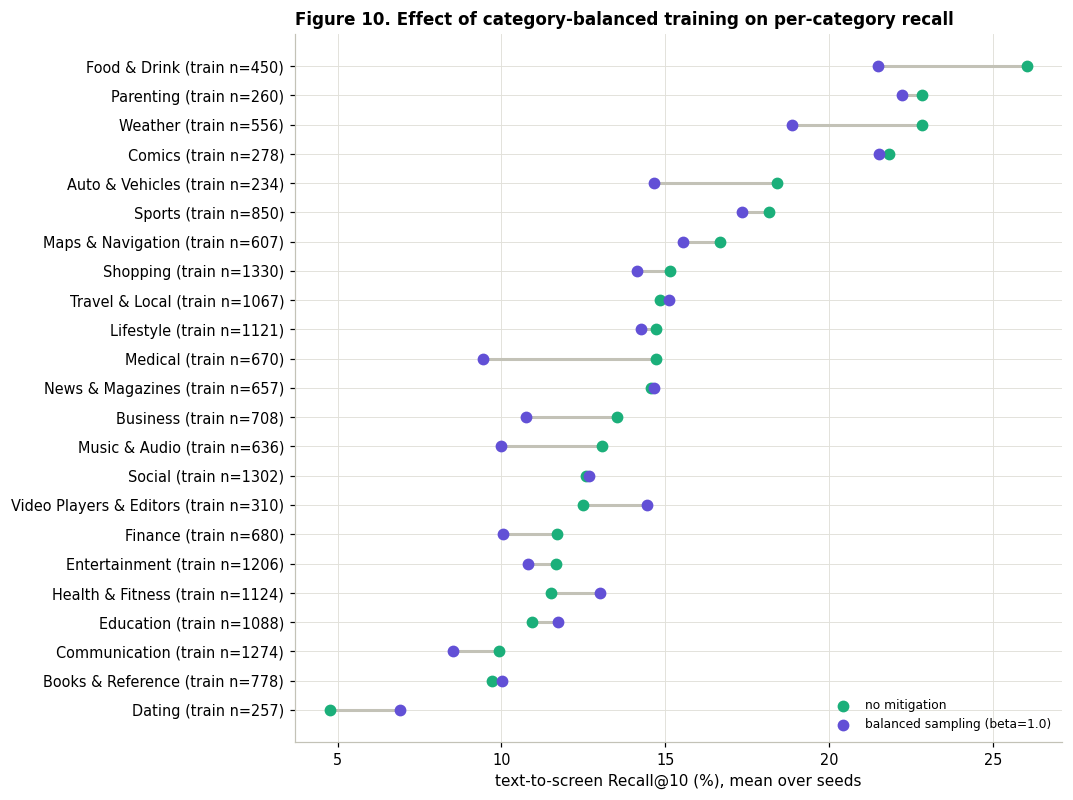

In [24]:
cat_train = meta_c["category_clean"].values[D["train"]["screens"]]
ranked_cats = [c for c in pd.unique(cat_img) if c != "Unknown" and (cat_img == c).sum() >= CFG["MIN_CAT_SCREENS"]]


def category_summary(h):
    per = {c: h[cat_cap == c].mean() * 100 for c in ranked_cats}
    v = np.array(list(per.values())) if per else np.array([np.nan])
    return dict(micro=h.mean() * 100, macro=np.nanmean(v), worst=np.nanmin(v), best=np.nanmax(v), gap=np.nanmax(v) - np.nanmin(v),
                sd_across_categories=np.nanstd(v)), per


mit_rows, MIT_PER = [], {}
for s_ in CFG["SEEDS"]:
    hb = (RESULTS["Contrastive"][CFG["SEEDS"].index(s_)]["ranks"]["t2i"] <= 10).astype(float)
    summ, per = category_summary(hb); mit_rows.append(dict(config="no mitigation", beta=0.0, seed=s_, avg_R10=RESULTS["Contrastive"][CFG["SEEDS"].index(s_)]["test"]["avg_R10"], **summ))
    MIT_PER.setdefault(0.0, []).append(per)
for beta in CFG["MITIGATION_BETAS"]:
    counts = pd.Series(cat_train).map(pd.Series(cat_train).value_counts()).values.astype(float)
    w = to_dev(counts ** -beta)
    for s_ in CFG["SEEDS"]:
        r = train("contrastive", D, s_, sample_weights=w)
        m, rk = evaluate(r["model"].score_matrix(D["test"]["XI"], D["test"]["XT"]), D["test"], lenient=False)
        summ, per = category_summary((rk["t2i"] <= 10).astype(float))
        mit_rows.append(dict(config=f"balanced sampling, beta={beta}", beta=beta, seed=s_, avg_R10=m["avg_R10"], **summ))
        MIT_PER.setdefault(beta, []).append(per)
mit = pd.DataFrame(mit_rows)
mit_tbl = mit.groupby("config", sort=False)[["avg_R10", "micro", "macro", "worst", "best", "gap", "sd_across_categories"]].agg(["mean", "std"])
mit_tbl.columns = [f"{a}_{b}" for a, b in mit_tbl.columns]
print("Table 13: category-balanced sampling as a bias mitigation (contrastive, text-to-screen R@10 %, mean and sd over seeds)")
display(mit_tbl.round(2)); save_tbl(mit_tbl, "t13_mitigation")
ev("mitigation", mit.groupby("config", sort=False)[["avg_R10", "macro", "worst", "gap"]].mean().round(2).to_dict("index"))
base_gap = mit[mit.beta == 0]["gap"].mean()
ev("mitigation_gap_change_pts", {b: mit[mit.beta == b]["gap"].mean() - base_gap for b in CFG["MITIGATION_BETAS"]})
ev("mitigation_overall_change_pts", {b: mit[mit.beta == b]["avg_R10"].mean() - mit[mit.beta == 0]["avg_R10"].mean() for b in CFG["MITIGATION_BETAS"]})

# figure: per-category recall without and with the strongest balancing
if ranked_cats:
    b_hi = max(CFG["MITIGATION_BETAS"])
    base = pd.DataFrame(MIT_PER[0.0]).mean(); bal = pd.DataFrame(MIT_PER[b_hi]).mean()
    order = base.sort_values().index; y = np.arange(len(order))
    fig, ax = plt.subplots(figsize=(9, max(3.5, 0.32 * len(order) + 1)))
    ax.hlines(y, base[order], bal[order], color="#c3c2b7", lw=2)
    ax.scatter(base[order], y, s=45, color=METHOD_COLOR["Contrastive"], label="no mitigation", zorder=3)
    ax.scatter(bal[order], y, s=45, color=C["violet"], label=f"balanced sampling (beta={b_hi})", zorder=3)
    ax.set_yticks(y); ax.set_yticklabels([f"{c} (train n={int((cat_train == c).sum())})" for c in order])
    ax.set_xlabel("text-to-screen Recall@10 (%), mean over seeds"); ax.legend(loc="lower right", fontsize=8)
    ax.set_title("Figure 10. Effect of category-balanced training on per-category recall", loc="left", fontweight="bold")
    save_fig(fig, "fig10_mitigation")

### 15.3 Failure analysis: where and why retrieval fails
* by caption genericity (how many screens in the whole dataset share the exact caption text) and caption length;
* what the top-1 wrong answer has in common with the target (same caption text, same app, same category, visual
  near-duplicate), which separates genuine errors from ambiguous ground truth.

[evidence] t2i_R10_by_genericity = {'unique': {'n': 5880, 'strict': 15.0, 'lenient': 15.0}, '2-5': {'n': 1254, 'strict': 18.6, 'lenient': 20.5}, '6-50': {'n': 833, 'strict': 15.8, 'lenient': 29.2}, '>50': {'n': 480, 'strict': 8.7, 'lenient': 66.2}}
[evidence] top1_error_anatomy = {'top1_errors': 8245, 'share_of_queries': 0.9761, 'wrong_screen_has_identical_caption': 0.0126, 'same_app': 0.0148, 'same_category': 0.1461, 'visual_near_duplicate': 0.0018}


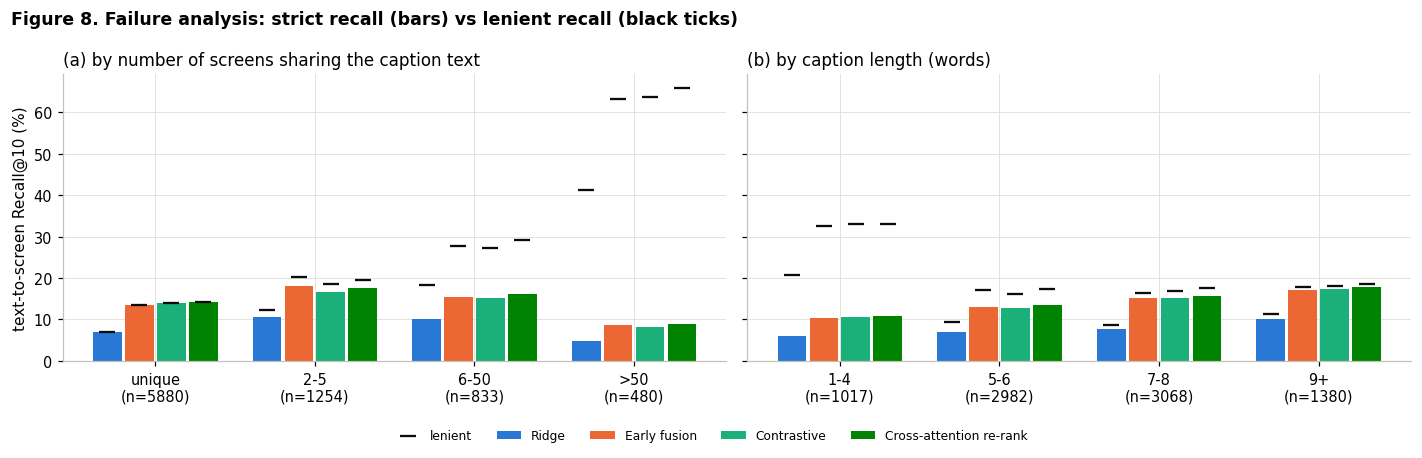

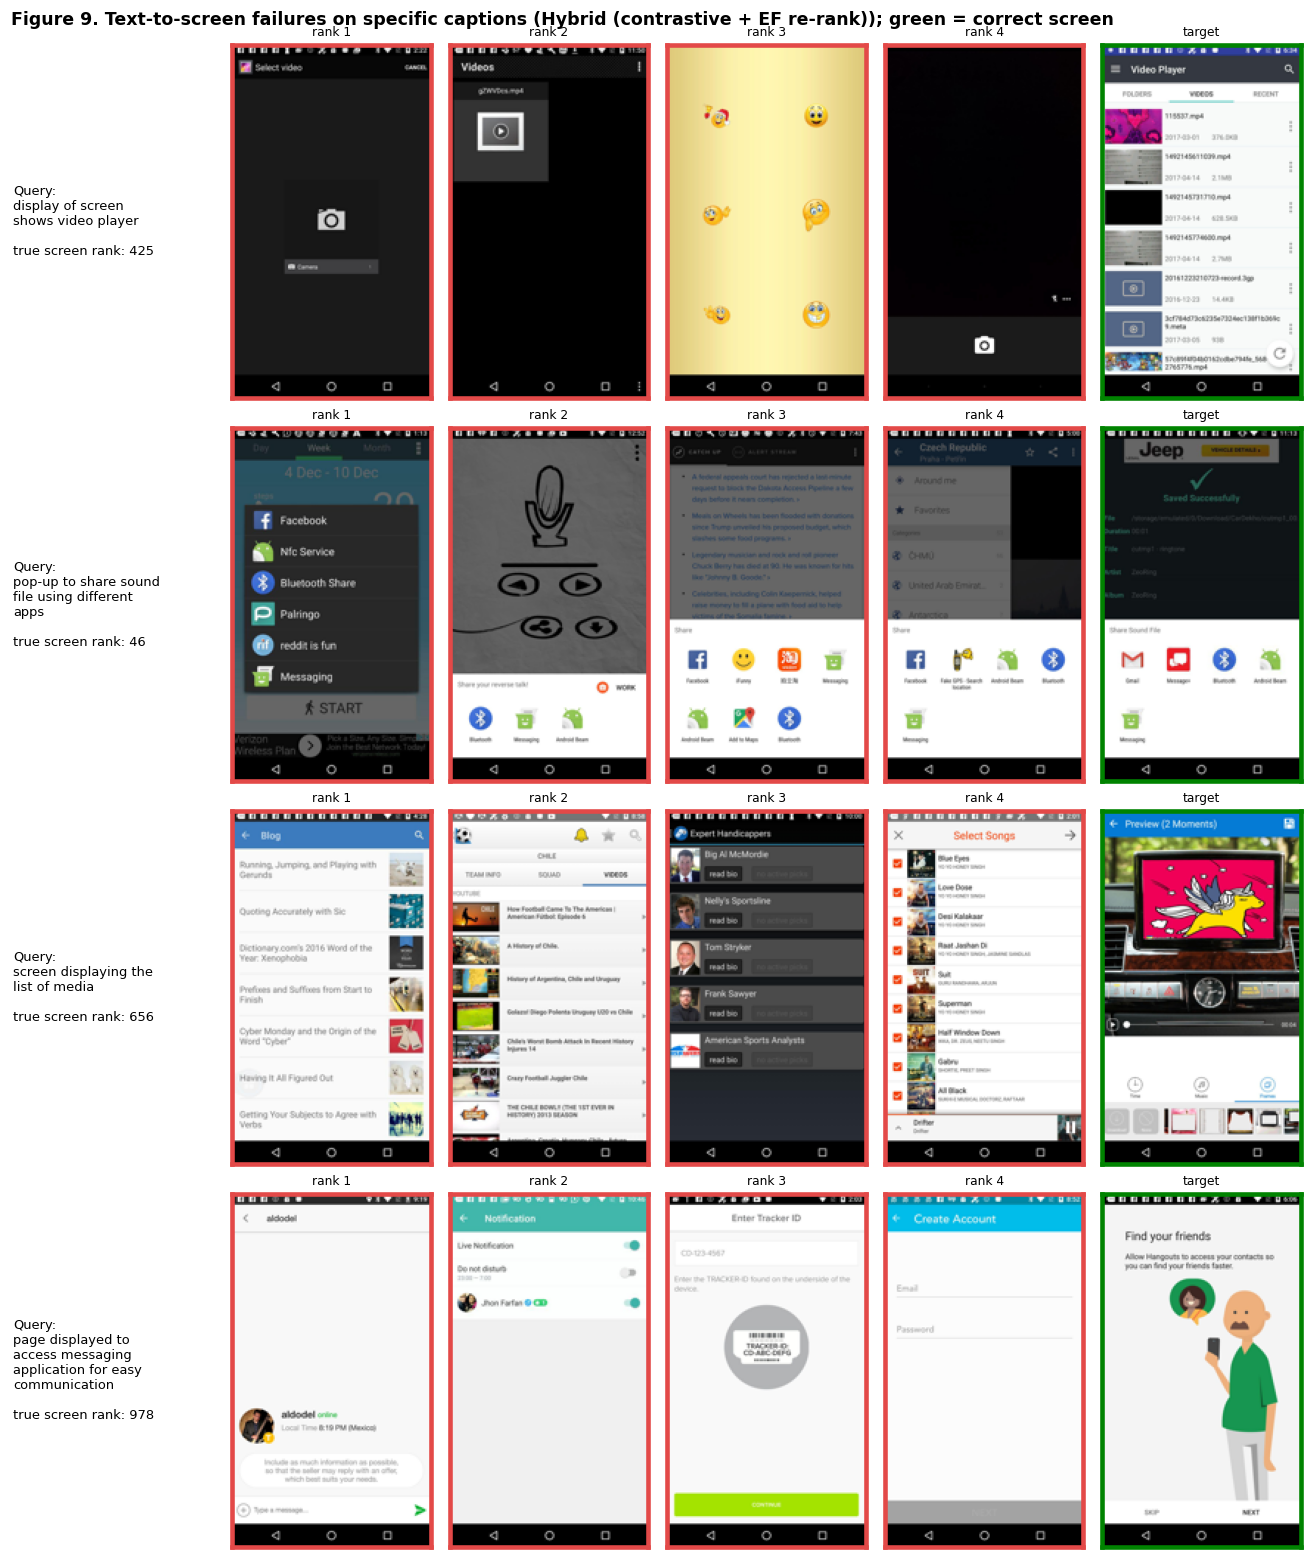

In [25]:
gen = cap_generic[te["cap_ids"]]; lens_ = np.array([len(cap_text[c].split()) for c in te["cap_ids"]])
fb = pd.cut(gen, [0, 1, 5, 50, 1e9], labels=["unique", "2-5", "6-50", ">50"])
lb = pd.cut(lens_, [0, 4, 6, 8, 100], labels=["1-4", "5-6", "7-8", "9+"])
fa_rows = []
for name in [n for n in ["Ridge", "Early fusion", "Contrastive", "Cross-attention re-rank", best_name] if n in RESULTS]:
    hs, hl = hits(name, "t2i", 10), hits(name, "t2i_len", 10)
    for b in fb.categories:
        fa_rows.append(dict(method=name, factor="genericity", bucket=b, n=int((fb == b).sum()), strict=hs[fb == b].mean() * 100, lenient=hl[fb == b].mean() * 100))
    for b in lb.categories:
        fa_rows.append(dict(method=name, factor="length (words)", bucket=b, n=int((lb == b).sum()), strict=hs[lb == b].mean() * 100, lenient=hl[lb == b].mean() * 100))
fa = pd.DataFrame(fa_rows).drop_duplicates(["method", "factor", "bucket"])
save_tbl(fa, "t16_failure_buckets", index=False)
ev("t2i_R10_by_genericity", fa[(fa.factor == "genericity") & (fa.method == best_name)].set_index("bucket")[["n", "strict", "lenient"]].round(1).to_dict("index"))

# top-1 error anatomy for the best model (seed 0 matrix)
S_best = SMAT[best_name][1].float()                     # t2i score matrix of the first seed
top1 = S_best.T.argmax(1).cpu().numpy(); tgt = cl_t2i; wrong = top1 != tgt
tgt_s, pred_s = te["screens"][tgt[wrong]], te["screens"][top1[wrong]]
caps_of = lambda m: {cap_norm[c] for c in range(cap_start[m], cap_start[m] + cap_cnt[m])}
Fi = F.normalize(to_dev(FEATS["resnet50"].astype(np.float32)), dim=-1)
vis = (Fi[torch.as_tensor(tgt_s, device=DEVICE)] * Fi[torch.as_tensor(pred_s, device=DEVICE)]).sum(1).cpu().numpy()
anat = dict(top1_errors=int(wrong.sum()), share_of_queries=float(wrong.mean()),
            wrong_screen_has_identical_caption=float(np.mean([cap_norm[c] in caps_of(p) for c, p in zip(te["cap_ids"][wrong], pred_s)])),
            same_app=float(np.mean(meta_c["app_package_name"].values[tgt_s] == meta_c["app_package_name"].values[pred_s])),
            same_category=float(np.mean(meta_c["category_clean"].values[tgt_s] == meta_c["category_clean"].values[pred_s])),
            visual_near_duplicate=float((vis > CFG["NEAR_DUP_T"]).mean()))
ev("top1_error_anatomy", anat); del Fi

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharey=True)
names_fa = [n for n in ["Ridge", "Early fusion", "Contrastive", "Cross-attention re-rank"] if n in RESULTS]
for j, fac in enumerate(["genericity", "length (words)"]):
    sub = fa[fa.factor == fac]; cats = list(sub.bucket.unique()); w = 0.8 / len(names_fa)
    for i, name in enumerate(names_fa):
        v = sub[sub.method == name].set_index("bucket").reindex(cats)
        x = np.arange(len(cats)) + (i - (len(names_fa) - 1) / 2) * w
        ax[j].bar(x, v["strict"], w * 0.9, color=METHOD_COLOR[name], label=f"{name}")
        ax[j].scatter(x, v["lenient"], marker="_", s=120, color=INK, zorder=3, label="lenient" if i == 0 else None)
    ax[j].set_xticks(range(len(cats))); n_lab = sub[sub.method == names_fa[0]].set_index("bucket").reindex(cats)["n"]
    ax[j].set_xticklabels([f"{c}\n(n={n})" for c, n in zip(cats, n_lab)])
    ax[j].set_title(["(a) by number of screens sharing the caption text", "(b) by caption length (words)"][j], loc="left")
ax[0].set_ylabel("text-to-screen Recall@10 (%)")
h_, l_ = ax[0].get_legend_handles_labels(); fig.legend(h_, l_, loc="lower center", ncol=len(l_), fontsize=8, bbox_to_anchor=(0.5, -0.08))
fig.suptitle("Figure 8. Failure analysis: strict recall (bars) vs lenient recall (black ticks)", fontweight="bold", x=0.01, ha="left")
fig.tight_layout(); save_fig(fig, "fig08_failure_buckets")

# qualitative: worst text-to-screen failures among specific (unique) captions, PII screens never shown
excl = set(CFG["PII_EXCLUDE_ROWS"])
r_best = np.stack([r["ranks"]["t2i"] for r in RESULTS[best_name]]).mean(0)
cand = np.where((gen == 1) & (r_best > 10))[0]
qs = np.random.default_rng(3).choice(cand, min(4, len(cand)), replace=False) if len(cand) else []
if len(qs):
    fig, axes = plt.subplots(len(qs), 6, figsize=(12, 3.6 * len(qs)), squeeze=False)
    for qi, q in enumerate(qs):
        a0 = axes[qi, 0]; a0.axis("off")
        a0.text(0, 0.5, "Query:\n" + textwrap.fill(cap_text[te["cap_ids"][q]], 22) + f"\n\ntrue screen rank: {int(r_best[q])}", fontsize=8.5, va="center")
        for j, idx in enumerate(S_best[:, q].topk(4).indices.cpu().numpy().tolist() + [int(cl_t2i[q])]):
            a = axes[qi, j + 1]; row = int(meta_c["_row"].values[te["screens"][idx]])
            if row in excl: a.axis("off"); continue
            a.imshow(open_screen(row).convert("RGB").resize((135, 240))); a.set_xticks([]); a.set_yticks([]); a.grid(False)
            col = C["green"] if idx == cl_t2i[q] else C["red"]
            for sp in a.spines.values(): sp.set_visible(True); sp.set_edgecolor(col); sp.set_linewidth(3)
            a.set_title("target" if j == 4 else f"rank {j + 1}", fontsize=8)
    fig.suptitle(f"Figure 9. Text-to-screen failures on specific captions ({best_name}); green = correct screen",
                 fontweight="bold", x=0.01, ha="left"); fig.tight_layout(); save_fig(fig, "fig09_failure_examples")

## 16. Changes from the proposal (generated from what actually ran)

In [26]:
# Compare the original research proposal with the final implementation, documenting methodological changes and their supporting evidence

changes = [
    ("Split", "Group apps linked by near-duplicates (cos > 0.95)", SPLIT_STRATEGY,
     f"largest linked component = {EVIDENCE['largest_component_share']:.1%} of screens; leakage after split = {EVIDENCE['leakage_final_split_val_test']}"),
    ("Image encoder", "ResNet-50", f"{IMG_KEY} (chosen on validation from {', '.join(IMG_KEYS)})", "Table 3"),
    ("Text pooling", "BERT mean pooling", TXT_KEY, "re-tested on full data, Table 3"),
    ("Early fusion objective", "MLP match score (2.1 used BCE + 7 negatives)", "in-batch multi-positive softmax, BCE kept as ablation",
     "same loss as the dual encoder isolates the architecture; Table 5"),
    ("Early fusion scoring", "pairwise MLP", "decomposed first fusion layer (exactly equivalent)", "makes all-pairs training and full-gallery evaluation feasible"),
    ("Contrastive loss", "all five captions are positives", "plus identical-text captions as positives", "32% of captions are reused across screens"),
    ("Evaluation", "R@1/5/10, MRR, bootstrap CIs", "+ median rank, lenient protocol, cluster bootstrap, 1K-gallery folds, paired tests", "Section 12"),
    ("Third fusion technique", "not in proposal", "cross-attention (intermediate) fusion as a top-K re-ranker with hard-negative batches",
     "adds attention-based fusion from the brief; Section 10.2"),
    ("Bias mitigation", "macro recall + CIs to separate noise from disparity", "plus category-balanced sampling tested as a mitigation",
     "Section 15.2, Table 13"),
    ("CLIP reference", "zero-shot", "zero-shot (fixed v5 API) + CLIP features with our head", "Section 10.2"),
    ("Privacy", "exclude screens with personal information", f"{len(CFG['PII_EXCLUDE_ROWS'])} manual-review screens excluded, never displayed", "Section 2.4"),
]
chg = pd.DataFrame(changes, columns=["aspect", "proposal", "implementation", "evidence / reason"])
print("Table 14: changes from proposal"); display(chg); save_tbl(chg, "t14_changes", index=False)

Table 14: changes from proposal


,aspect,proposal,implementation,evidence / reason
0,Split,Group apps linked by near-duplicates (cos > 0.95),app-level split + purge of val/test screens wi...,largest linked component = 61.6% of screens; l...
1,Image encoder,ResNet-50,"vit_b_16 (chosen on validation from resnet50, ...",Table 3
2,Text pooling,BERT mean pooling,bert_mean,"re-tested on full data, Table 3"
3,Early fusion objective,MLP match score (2.1 used BCE + 7 negatives),"in-batch multi-positive softmax, BCE kept as a...",same loss as the dual encoder isolates the arc...
4,Early fusion scoring,pairwise MLP,decomposed first fusion layer (exactly equival...,makes all-pairs training and full-gallery eval...
5,Contrastive loss,all five captions are positives,plus identical-text captions as positives,32% of captions are reused across screens
6,Evaluation,"R@1/5/10, MRR, bootstrap CIs","+ median rank, lenient protocol, cluster boots...",Section 12
7,Third fusion technique,not in proposal,cross-attention (intermediate) fusion as a top...,adds attention-based fusion from the brief; Se...
8,Bias mitigation,macro recall + CIs to separate noise from disp...,plus category-balanced sampling tested as a mi...,"Section 15.2, Table 13"
9,CLIP reference,zero-shot,zero-shot (fixed v5 API) + CLIP features with ...,Section 10.2


## FACT SHEET

In [27]:
CFG_TBL = pd.DataFrame([{"setting": k, "value": str(v)} for k, v in CFG.items()]); save_tbl(CFG_TBL, "t15_config", index=False)
EVIDENCE["config"] = {k: str(v) for k, v in CFG.items()}
with open(OUT / "evidence.json", "w") as f:
    json.dump(EVIDENCE, f, indent=2, default=str)
sheet = [" REPORT FACT SHEET "]
for k, v in EVIDENCE.items():
    if k != "config": sheet.append(f"{k}: {v}")
sheet += ["", "Table 6 (strict test results):", main_tbl.to_string(), "", "Table 7 (lenient):", len_tbl.to_string(),
          "", "Table 5 (ablations):", abl_sum.round(2).to_string() if len(abl) else "skipped",
          "", "Table 12 (per category):", cat_tbl.round(1).to_string(),
          "", "Table 13 (mitigation):", mit_tbl.round(2).to_string(), "", "Table 14 (changes):", chg.to_string()]
sheet = "\n".join(sheet); print(sheet)
open(OUT / "report_fact_sheet.txt", "w").write(sheet)
shutil.make_archive("p22_outputs", "zip", OUT)
if IN_COLAB:
    shutil.copy("p22_outputs.zip", CACHE / "p22_outputs.zip")
    from google.colab import files
    files.download("p22_outputs.zip")
print("Saved outputs/ and p22_outputs.zip")

============================== REPORT FACT SHEET ==============================
python: 3.13.16
torch: 2.14.1+cu130
torchvision: 0.29.1+cu130
transformers: 5.22.1
datasets: 4.8.5
device: cuda
gpu_name: Tesla T4
dataset_id_used: rootsautomation/RICO-Screen2Words
original_split_sizes: {'train': 15743, 'val': 2364, 'test': 4310}
n_screens_raw: 22417
n_captions_raw: 112085
missing_values_per_column: {'screenId': 0, 'captions': 0, 'app_package_name': 0, 'play_store_name': 0, 'category': 0}
captions_per_screen: {'5': 22417}
empty_captions: 0
caption_words_median_p95_max: [7.0, 10.0, 12]
vocab_size: 6787
nonascii_caption_share: 0.0
share_captions_reused_across_screens: 0.3179
top_generic_captions: {'welcome page': 635, 'login page': 389, 'sign in page': 346, 'settings page': 296, 'sign up page': 250, 'display of a pop up': 208, 'home page': 202, 'page displaying different options': 192}
duplicate_captions_within_screen: 979
malformed_category_rows: 1
malformed_category_values: {'000 - 1': 1}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Saved outputs/ and p22_outputs.zip
